# Estimación de RUL en N-CMAPSS (DS02) — ProjectV02

**Trabajo de título:** *Estimación de la vida útil remanente en sistemas de propulsión
aeronáutica mediante arquitecturas híbridas de aprendizaje profundo*
Matías Godoy Rojas — ROL 201821090-0 — Prof. guía: Mauricio Araya L.

Este notebook implementa, por etapas, lo acordado en la **Reunión 03**. El detalle de
cada etapa, sus criterios y sus decisiones está en `Plan_ProjectV02.md`.

| Etapa | Contenido | Estado |
|---|---|---|
| 0 | Infraestructura común: datos, normalización, arquitecturas, entrenamiento reanudable, métricas y reporte | Completada |
| 1 | Línea base y ablación de arquitecturas (A1–A6) | Completada |
| 2 | Normalización por condición de operación | Completada |
| 3 | Pérdida asimétrica sobre el mecanismo de atención elegido | Completada |
| 4 | Validación cruzada dejando una unidad fuera y evaluación final en prueba | Completada |
| 5 | Diagramas didácticos (`Diagramas.md`) | Completada |
| 6 | Consolidación y defensa (`Preparacion_Defensa.md`) | Completada |

**Principio del diseño:** se cambia un factor por etapa (arquitectura → normalización
→ pérdida) y la elección de cada etapa queda fija para la siguiente.

**Cómo re-ejecutar.** Cada entrenamiento se guarda en `results/runs/`. Al volver a
ejecutar el notebook, los entrenamientos ya completos se cargan desde disco en vez de
repetirse, de modo que agregar una etapa solo cuesta el cómputo de esa etapa.

# Etapa 0 — Infraestructura común

## 0.1 Dependencias

Si falta alguna, descomentar y ejecutar una sola vez:

```python
%pip install h5py scikit-learn torch pandas numpy matplotlib seaborn
```

In [1]:
import os
import json
import math
import time
import random
import hashlib
import warnings

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore", category=UserWarning)

%matplotlib inline

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | dispositivo activo: {device}")

PyTorch 2.7.1+cpu | dispositivo activo: cpu


## 0.2 Configuración

Todos los hiperparámetros viven aquí. Cualquier cambio en el bloque de
entrenamiento cambia el *hash* de configuración, y con él el identificador de cada
corrida: el notebook reentrena en vez de reutilizar resultados obtenidos con otra
configuración.

`SMOKE_TEST = True` ejecuta todo con datos reducidos y dos épocas, en un directorio de
corridas separado, para verificar que el código corre de principio a fin.

In [2]:
SMOKE_TEST = False

DATASET_PATH = "D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5"
OUT_DIR = "results"
RUNS_DIR = os.path.join(OUT_DIR, "runs_smoke" if SMOKE_TEST else "runs")
SELECTION_FILE = os.path.join(OUT_DIR, "seleccion.json")
V01_RESULTS = "../ProjectV01/results/metrics_val.csv"
os.makedirs(RUNS_DIR, exist_ok=True)

# --- Datos ---
SAMPLE_STEP = 10            # 1 muestra cada 10 s (datos originales a 1 Hz)
WINDOW_SIZE = 30            # 30 pasos x 10 s = 300 s de vuelo por ventana
STRIDE = 10
USE_PWL = True              # recorte lineal por tramos, umbral derivado de 'hs'

# --- Partición oficial por unidad ---
TRAIN_UNITS = [2.0, 5.0, 10.0, 16.0]
VAL_UNITS = [18.0, 20.0]
# prueba = partición 'test' del HDF5: unidades 11, 14, 15

# --- Zonas de evaluación (ciclos de RUL restantes) ---
FINAL_ZONE = 20.0           # zona final: métrica principal (criterio de la Reunión 03)
ZONES = [("Final", 0.0, 20.0), ("Intermedia", 20.0, 40.0), ("Temprana", 40.0, np.inf)]

# --- Modelos ---
CONV_CHANNELS = 32
HIDDEN_SIZE = 64
DROPOUT = 0.2

# --- Entrenamiento ---
SEEDS = [0, 1, 2, 3, 4]
BATCH_SIZE = 256
MAX_EPOCHS = 30
PATIENCE = 5
LR = 1e-3
WEIGHT_DECAY = 1e-4

if SMOKE_TEST:
    SEEDS = [0]
    MAX_EPOCHS = 2
    PATIENCE = 2

HP = dict(SAMPLE_STEP=SAMPLE_STEP, WINDOW_SIZE=WINDOW_SIZE, STRIDE=STRIDE, USE_PWL=USE_PWL,
          CONV_CHANNELS=CONV_CHANNELS, HIDDEN_SIZE=HIDDEN_SIZE, DROPOUT=DROPOUT,
          BATCH_SIZE=BATCH_SIZE, MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, LR=LR,
          WEIGHT_DECAY=WEIGHT_DECAY, SMOKE_TEST=SMOKE_TEST)
HP_HASH = hashlib.md5(json.dumps(HP, sort_keys=True).encode()).hexdigest()[:8]

# --- Estilo de figuras ---
# Colores fijos por arquitectura (paleta categórica de referencia). A5 y A3 conservan
# los colores que tenían en v01 (atención = azul, último estado = naranjo).
ARCH_COLORS = {"A5": "#2a78d6", "A3": "#eb6834", "A1": "#1baf7a",
               "A2": "#eda100", "A4": "#e87ba4", "A6": "#008300"}
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

print(f"Modo: {'SMOKE TEST' if SMOKE_TEST else 'CORRIDA DEFINITIVA'} | "
      f"hash de configuración: {HP_HASH} | corridas en: {RUNS_DIR}")

Modo: CORRIDA DEFINITIVA | hash de configuración: 405955a4 | corridas en: results\runs


## 0.3 Carga desde HDF5

Se usan las 4 condiciones de operación `W` (alt, Mach, TRA, T2) y los 14 sensores
físicos `X_s`. Se descartan los sensores virtuales `X_v` y los parámetros de salud
`T`, que no son medibles en un motor real. Además de la unidad, el ciclo y el
indicador de salud `hs`, se conserva la clase de vuelo `Fc` para la etapa 2.

In [3]:
def _names(f, key):
    return [v.decode() if isinstance(v, bytes) else str(v) for v in np.array(f[key]).flatten()]


def load_ncmapss(file_path, sample_step=10, cache_dir=OUT_DIR):
    """Particiones oficiales 'dev' y 'test' con submuestreo y caché en disco."""
    cache = os.path.join(cache_dir, f"cache_step{sample_step}.npz")
    meta_file = os.path.join(cache_dir, f"cache_step{sample_step}_vars.json")
    keys = ("features", "rul", "unit", "cycle", "fc", "hs")

    if os.path.exists(cache) and os.path.exists(meta_file):
        z = np.load(cache)
        if all(f"{s}_{k}" in z for s in ("dev", "test") for k in keys):
            print(f"Cargando desde caché: {cache}")
            with open(meta_file, encoding="utf-8") as fh:
                var_names = json.load(fh)
            return {s: {k: z[f"{s}_{k}"] for k in keys} for s in ("dev", "test")}, var_names
        print("La caché no contiene todas las variables necesarias; se regenera.")

    data = {}
    print(f"Leyendo {file_path} (submuestreo 1/{sample_step})...")
    with h5py.File(file_path, "r") as f:
        var_names = {"W": _names(f, "W_var"), "X_s": _names(f, "X_s_var"), "A": _names(f, "A_var")}
        for split in ("dev", "test"):
            W = np.array(f[f"W_{split}"][::sample_step], dtype=np.float32)
            Xs = np.array(f[f"X_s_{split}"][::sample_step], dtype=np.float32)
            Y = np.array(f[f"Y_{split}"][::sample_step], dtype=np.float32).ravel()
            A = np.array(f[f"A_{split}"][::sample_step], dtype=np.float32)
            data[split] = {"features": np.hstack([W, Xs]).astype(np.float32), "rul": Y,
                           "unit": A[:, 0], "cycle": A[:, 1], "fc": A[:, 2], "hs": A[:, 3]}
            print(f"  {split:4s}: {len(Y):>7d} registros")
    np.savez_compressed(cache, **{f"{s}_{k}": v for s, d in data.items() for k, v in d.items()})
    with open(meta_file, "w", encoding="utf-8") as fh:
        json.dump(var_names, fh, ensure_ascii=False, indent=2)
    return data, var_names


data, var_names = load_ncmapss(DATASET_PATH, SAMPLE_STEP)
dev, test = data["dev"], data["test"]
FEATURE_NAMES = var_names["W"] + var_names["X_s"]
NUM_FEATURES = len(FEATURE_NAMES)
print(f"Canales de entrada ({NUM_FEATURES}): {FEATURE_NAMES}")

Cargando desde caché: results\cache_step10.npz


Canales de entrada (18): ['alt', 'Mach', 'TRA', 'T2', 'T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']


## 0.4 Caracterización: umbral PwL, zonas de evaluación y clases de vuelo

In [4]:
rows = []
for split, d in (("dev", dev), ("test", test)):
    for u in np.unique(d["unit"]):
        m = d["unit"] == u
        deg = d["rul"][m & (d["hs"] == 0)]
        fc_vals = np.unique(d["fc"][m]).astype(int)
        rows.append({"Partición": split, "Unidad": int(u), "Registros": int(m.sum()),
                     "Ciclos (EOL)": int(d["cycle"][m].max()),
                     "RUL en transición sano→degradado": float(deg.max()),
                     "Clase de vuelo Fc": ", ".join(map(str, fc_vals))})
units_df = pd.DataFrame(rows)
print(units_df.to_string(index=False))

# Umbral PwL: mediana del RUL en la transición sano→degradado (unidades de entrenamiento)
_tr = units_df[(units_df["Partición"] == "dev") & units_df["Unidad"].isin([int(u) for u in TRAIN_UNITS])]
RUL_MAX = float(np.round(_tr["RUL en transición sano→degradado"].median()))
rul_dev = np.clip(dev["rul"], 0.0, RUL_MAX) if USE_PWL else dev["rul"].copy()
rul_test = np.clip(test["rul"], 0.0, RUL_MAX) if USE_PWL else test["rul"].copy()
print(f"\nUmbral PwL: {RUL_MAX:.0f} ciclos")

print("\nFracción de registros por zona de evaluación:")
for name, lo, hi in ZONES:
    fd = np.mean((rul_dev > lo) & (rul_dev <= hi)) if lo > 0 else np.mean(rul_dev <= hi)
    ft = np.mean((rul_test > lo) & (rul_test <= hi)) if lo > 0 else np.mean(rul_test <= hi)
    print(f"   {name:<11} ({lo:>4.0f}, {hi:>4.0f}]  dev {100 * fd:5.1f} %  |  prueba {100 * ft:5.1f} %")

Partición  Unidad  Registros  Ciclos (EOL)  RUL en transición sano→degradado Clase de vuelo Fc
      dev       2      85315            75                              58.0                 3
      dev       5     103342            89                              72.0                 3
      dev      10      95271            82                              65.0                 3
      dev      16      76529            63                              47.0                 3
      dev      18      89072            71                              54.0                 3
      dev      20      76816            66                              49.0                 3
     test      11      66350            59                              40.0                 3
     test      14      15678            76                              40.0                 1
     test      15      43347            67                              43.0                 2

Umbral PwL: 62 ciclos

Fracción de registros por 

**Observación sobre `Fc` (relevante para la etapa 2).** La clase de vuelo es constante
por motor y **todas las unidades de `dev` son `Fc = 3`**. Las unidades de prueba 14 y
15 pertenecen a clases de vuelo (`Fc = 1` y `Fc = 2`) que no aparecen en entrenamiento
ni en validación. Normalizar literalmente por `Fc` con estadísticas de entrenamiento no
es posible para esas unidades, y en `dev` sería idéntico a la normalización global. Las
alternativas se discuten en `Plan_ProjectV02.md`, etapa 2.

Este mismo hecho explica, al menos en parte, el sesgo optimista mayor en prueba que en
validación observado en v01: las unidades 14 y 15 vuelan perfiles que el modelo nunca vio.

## 0.5 Particiones por unidad

Una partición se describe por sus unidades de entrenamiento, de validación y de
evaluación. La partición `oficial` evalúa sobre el conjunto de prueba del HDF5; la
etapa 4 agregará una partición por cada fold de validación cruzada.

In [5]:
SPLITS = {"oficial": {"name": "oficial", "train": TRAIN_UNITS, "val": VAL_UNITS, "eval": "test"}}

_n_tr = np.isin(dev["unit"], TRAIN_UNITS).sum()
_n_va = np.isin(dev["unit"], VAL_UNITS).sum()
_n_te = len(test["unit"])
_n = _n_tr + _n_va + _n_te
assert not np.any(np.isin(TRAIN_UNITS, VAL_UNITS))
assert len(np.intersect1d(np.unique(dev["unit"]), np.unique(test["unit"]))) == 0
print("Partición oficial (registros submuestreados):")
print(f"   Entrenamiento  unidades  2, 5, 10, 16 : {_n_tr:>7,d}  ({100 * _n_tr / _n:4.1f} %)")
print(f"   Validación     unidades 18, 20        : {_n_va:>7,d}  ({100 * _n_va / _n:4.1f} %)")
print(f"   Prueba         unidades 11, 14, 15    : {_n_te:>7,d}  ({100 * _n_te / _n:4.1f} %)")

Partición oficial (registros submuestreados):
   Entrenamiento  unidades  2, 5, 10, 16 : 360,457  (55.3 %)
   Validación     unidades 18, 20        : 165,888  (25.5 %)
   Prueba         unidades 11, 14, 15    : 125,375  (19.2 %)


## 0.6 Normalización extensible y sin fuga

`fit_normalizer(método, …)` aprende **solo** de las unidades de entrenamiento de la
partición y devuelve una función que transforma cualquier conjunto. En la etapa 0 se
implementa `global` (estandarización de los 18 canales, como en v01); los métodos de
la etapa 2 se registran en el mismo diccionario.

In [6]:
def _fit_global(d, train_mask):
    scaler = StandardScaler().fit(d["features"][train_mask])
    return lambda dd: scaler.transform(dd["features"]).astype(np.float32)


NORMALIZERS = {"global": _fit_global}


def fit_normalizer(method, d, train_mask):
    if method not in NORMALIZERS:
        raise ValueError(f"Normalización '{method}' no implementada: {list(NORMALIZERS)}")
    return NORMALIZERS[method](d, train_mask)

## 0.7 Ventaneo y construcción de tensores

Las posiciones de las ventanas no dependen de la normalización, así que se calculan
una sola vez: ventanas de 30 pasos que nunca cruzan la frontera entre dos ciclos de
vuelo, con etiqueta igual al RUL del último instante. `build_tensors` aplica la
normalización pedida y memoriza el resultado.

In [7]:
def _window_starts(d):
    key = np.stack([d["unit"], d["cycle"]], axis=1)
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    bounds = np.concatenate([[0], np.where(change)[0] + 1, [len(d["unit"])]])
    starts = [s + np.arange((e - s - WINDOW_SIZE) // STRIDE + 1) * STRIDE
              for s, e in zip(bounds[:-1], bounds[1:]) if e - s >= WINDOW_SIZE]
    starts = np.concatenate(starts)
    last = starts + WINDOW_SIZE - 1
    return starts, d["unit"][last], d["cycle"][last]


WINDOWS = {"dev": _window_starts(dev), "test": _window_starts(test)}
_RUL = {"dev": rul_dev, "test": rul_test}


def _gather(feats, source, units=None):
    starts, w_unit, w_cycle = WINDOWS[source]
    m = np.ones(len(starts), bool) if units is None else np.isin(w_unit, units)
    st = starts[m]
    X = feats[st[:, None] + np.arange(WINDOW_SIZE)[None, :]].astype(np.float32)
    y = _RUL[source][st + WINDOW_SIZE - 1].astype(np.float32)
    meta = np.stack([w_unit[m], w_cycle[m]], axis=1)
    return X, y, meta


_TENSORS = {}


def build_tensors(norm, split_name):
    """Devuelve {'train','val','eval'} → (X, y, meta) para una normalización y partición."""
    key = (norm, split_name)
    if key in _TENSORS:
        return _TENSORS[key]
    sp = SPLITS[split_name]
    transform = fit_normalizer(norm, dev, np.isin(dev["unit"], sp["train"]))
    dev_n = transform(dev)
    out = {"train": _gather(dev_n, "dev", sp["train"]), "val": _gather(dev_n, "dev", sp["val"])}
    out["eval"] = (_gather(transform(test), "test") if sp["eval"] == "test"
                   else _gather(dev_n, "dev", sp["eval"]))
    if SMOKE_TEST:
        rng = np.random.default_rng(0)
        for part, n in (("train", 4000), ("val", 2000)):
            X, y, meta = out[part]
            sel = rng.choice(len(X), size=min(n, len(X)), replace=False)
            out[part] = (X[sel], y[sel], meta[sel])
    for a, b in (("train", "val"), ("train", "eval")):
        assert not np.intersect1d(np.unique(out[a][2][:, 0]), np.unique(out[b][2][:, 0])).size
    _TENSORS[key] = out
    return out


_T = build_tensors("global", "oficial")
for part in ("train", "val", "eval"):
    X, y, _ = _T[part]
    print(f"{part:<6}: X = {str(X.shape):>18s} | RUL medio = {y.mean():5.1f}")
print("OK: sin unidades compartidas entre entrenamiento, validación y evaluación.")

train : X =    (35287, 30, 18) | RUL medio =  37.1
val   : X =    (16251, 30, 18) | RUL medio =  33.3
eval  : X =    (12047, 30, 18) | RUL medio =  31.0
OK: sin unidades compartidas entre entrenamiento, validación y evaluación.


## 0.8 Catálogo de arquitecturas

Todas usan los mismos tamaños de bloque (32 canales convolucionales, 64 unidades
ocultas) y el mismo cabezal de regresión. Lo que se iguala es el tamaño de cada
bloque, **no** el número total de parámetros: este va de unos 10 mil (A1) a unos 33
mil (A5), y se reporta junto a cada resultado porque una arquitectura con más
parámetros puede rendir mejor solo por su mayor capacidad. Son versiones
**inspiradas** en los trabajos citados, no réplicas exactas.

| Id | Arquitectura | Extractor | Agregación temporal | Inspirada en |
|---|---|---|---|---|
| A1 | 1D-CNN | Conv 18→32 → Conv 32→64 | promedio | Sateesh Babu et al. (2016); Li, Ding y Sun (2018) |
| A2 | LSTM | LSTM 18→64 | último estado | Zheng et al. (2017); Wu et al. (2018) |
| A3 | CNN + LSTM | Conv 18→32 → LSTM 32→64 | último estado | — (= v01 `last`) |
| A4 | LSTM + atención | LSTM 18→64 | atención | de Oliveira da Costa et al. (2019) |
| A5 | CNN + LSTM + atención | Conv 18→32 → LSTM 32→64 | atención | Li et al. (2022) (= v01 `attention`) |
| A6 | CNN + atención | Conv 18→32 → Conv 32→64 | atención | — |

El dropout (0,2) se aplica a la salida de la primera convolución; en A2 y A4, que no
tienen bloque convolucional, se aplica a la secuencia de salida del LSTM.

**Reproducibilidad con v01:** en A3 y A5 los parámetros se crean en el mismo orden que
en v01 (conv, bn, lstm, atención, cabezal), así que con la misma semilla parten de la
misma inicialización.

In [8]:
class TemporalAttention(nn.Module):
    """Atención aditiva (Bahdanau) sobre la dimensión temporal."""

    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, h):                          # h: (B, T, H)
        weights = torch.softmax(self.v(torch.tanh(self.attn(h))), dim=1)   # (B, T, 1)
        return torch.sum(weights * h, dim=1), weights.squeeze(-1)


class RULNet(nn.Module):
    def __init__(self, num_features, use_cnn, use_lstm, aggregation,
                 conv_channels=CONV_CHANNELS, hidden=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        assert use_cnn or use_lstm
        assert aggregation in ("last", "mean", "attention")
        self.use_cnn, self.use_lstm, self.aggregation = use_cnn, use_lstm, aggregation
        if use_cnn:
            self.conv = nn.Conv1d(num_features, conv_channels, kernel_size=3, padding=1)
            self.bn = nn.BatchNorm1d(conv_channels)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        if use_cnn and not use_lstm:              # CNN pura: segunda conv hasta 'hidden'
            self.conv2 = nn.Conv1d(conv_channels, hidden, kernel_size=3, padding=1)
            self.bn2 = nn.BatchNorm1d(hidden)
        if use_lstm:
            self.lstm = nn.LSTM(conv_channels if use_cnn else num_features, hidden,
                                batch_first=True)
        self.attention = TemporalAttention(hidden) if aggregation == "attention" else None
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):                          # x: (B, T, F)
        h = x
        if self.use_cnn:
            z = self.dropout(self.relu(self.bn(self.conv(x.permute(0, 2, 1)))))
            if not self.use_lstm:
                z = self.relu(self.bn2(self.conv2(z)))
            h = z.permute(0, 2, 1)                 # (B, T, C)
        if self.use_lstm:
            h, _ = self.lstm(h)                    # (B, T, H)
            if not self.use_cnn:
                h = self.dropout(h)

        weights = None
        if self.aggregation == "attention":
            feat, weights = self.attention(h)
        elif self.aggregation == "mean":
            feat = h.mean(dim=1)
        else:
            feat = h[:, -1, :]
        return self.head(feat), weights


ARCHS = {
    "A1": dict(name="1D-CNN", use_cnn=True, use_lstm=False, aggregation="mean",
               ref="Sateesh Babu et al. (2016); Li, Ding y Sun (2018)"),
    "A2": dict(name="LSTM", use_cnn=False, use_lstm=True, aggregation="last",
               ref="Zheng et al. (2017); Wu et al. (2018)"),
    "A3": dict(name="CNN + LSTM", use_cnn=True, use_lstm=True, aggregation="last",
               ref="— (referencia por definir)"),
    "A4": dict(name="LSTM + atención", use_cnn=False, use_lstm=True, aggregation="attention",
               ref="de Oliveira da Costa et al. (2019)"),
    "A5": dict(name="CNN + LSTM + atención", use_cnn=True, use_lstm=True, aggregation="attention",
               ref="Li et al. (2022)"),
    "A6": dict(name="CNN + atención", use_cnn=True, use_lstm=False, aggregation="attention",
               ref="—"),
}


def make_model(arch):
    a = ARCHS[arch]
    return RULNet(NUM_FEATURES, a["use_cnn"], a["use_lstm"], a["aggregation"])


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


_x = torch.randn(4, WINDOW_SIZE, NUM_FEATURES)
rows = []
for k, a in ARCHS.items():
    m = make_model(k).eval()
    out, w = m(_x)
    assert out.shape == (4, 1) and (w is None) == (a["aggregation"] != "attention")
    rows.append({"Id": k, "Arquitectura": a["name"], "Agregación": a["aggregation"],
                 "Parámetros": f"{count_params(m):,}".replace(",", "."), "Inspirada en": a["ref"]})
print(pd.DataFrame(rows).to_string(index=False))

Id          Arquitectura Agregación Parámetros                                      Inspirada en
A1                1D-CNN       mean     10.273 Sateesh Babu et al. (2016); Li, Ding y Sun (2018)
A2                  LSTM       last     23.617             Zheng et al. (2017); Wu et al. (2018)
A3            CNN + LSTM       last     29.025                        — (referencia por definir)
A4       LSTM + atención  attention     27.841                de Oliveira da Costa et al. (2019)
A5 CNN + LSTM + atención  attention     33.249                                  Li et al. (2022)
A6        CNN + atención  attention     14.497                                                 —


## 0.9 Función de pérdida

$\mathcal{L}_\alpha = \frac{1}{N}\sum_i w(d_i)\,d_i^2$, con $d = \hat{y} - y$ y
$w = \alpha$ si $d > 0$ (sobreestimación) o $w = 1$ en otro caso. Con $\alpha = 1$ es
exactamente el MSE, que es la pérdida de las etapas 1 y 2. La etapa 3 explora
$\alpha > 1$.

Su minimizador es el **expectil** de nivel $\tau = 1/(1+\alpha)$ de la distribución
condicional del RUL (Newey y Powell, 1987, *Econometrica* 55(4), 819–847).

In [9]:
class AsymmetricMSELoss(nn.Module):
    def __init__(self, alpha=1.0):
        super().__init__()
        assert alpha >= 1.0
        self.alpha = float(alpha)

    def forward(self, pred, target):
        d = pred - target
        return torch.mean((1.0 + (self.alpha - 1.0) * (d > 0).float()) * d ** 2)


def asym_rmse(y_true, y_pred, alpha):
    d = np.asarray(y_pred).ravel() - np.asarray(y_true).ravel()
    return float(np.sqrt(np.mean((1.0 + (alpha - 1.0) * (d > 0)) * d ** 2)))


_p, _t = torch.randn(1000, 1) * 10, torch.randn(1000, 1) * 10
assert torch.allclose(AsymmetricMSELoss(1.0)(_p, _t), nn.MSELoss()(_p, _t))
_z = torch.zeros(1, 1)
assert torch.isclose(AsymmetricMSELoss(4.0)(_z + 3, _z), 4 * AsymmetricMSELoss(4.0)(_z - 3, _z))
print("OK: L_α con α = 1 coincide con el MSE; con α = 4 sobreestimar cuesta 4 veces más.")

OK: L_α con α = 1 coincide con el MSE; con α = 4 sobreestimar cuesta 4 veces más.


## 0.10 Métricas

La **zona final (RUL ≤ 20 ciclos)** es la métrica principal: lo que importa es la
precisión cuando el fallo está cerca, y la sobreestimación temprana es aceptable
(Reunión 03). Se reportan además las métricas globales, el RMSE por zona y por unidad.

Score NASA (Saxena et al., 2008): `exp(-d/13) - 1` si `d < 0`, `exp(d/10) - 1` si
`d ≥ 0`, normalizado por el número de muestras.

In [10]:
def rmse(y, p):
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    return float(np.sqrt(np.mean((p - y) ** 2))) if len(y) else np.nan


def nasa_score(y, p):
    d = np.asarray(p).ravel() - np.asarray(y).ravel()
    if not len(d):
        return np.nan
    return float(np.mean(np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)))


def _zone_mask(y, lo, hi):
    return (y > lo) & (y <= hi) if lo > 0 else (y <= hi)


def compute_metrics(y, p, meta=None):
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    d = p - y
    fin = y <= FINAL_ZONE
    out = {
        "RMSE final": rmse(y[fin], p[fin]),
        "Sobreest. media final": float(np.mean(np.clip(d[fin], 0, None))),
        "% sobreest. final": float(100 * np.mean(d[fin] > 0)),
        "Score NASA final": nasa_score(y[fin], p[fin]),
        "RMSE": rmse(y, p),
        "MAE": float(np.mean(np.abs(d))),
        "Score NASA": nasa_score(y, p),
        "Sesgo": float(np.mean(d)),
        "% sobreest.": float(100 * np.mean(d > 0)),
    }
    for name, lo, hi in ZONES[1:]:
        m = _zone_mask(y, lo, hi)
        out[f"RMSE {name.lower()}"] = rmse(y[m], p[m])
    if meta is not None:
        for u in np.unique(meta[:, 0]):
            m = meta[:, 0] == u
            out[f"RMSE u{int(u)}"] = rmse(y[m], p[m])
            out[f"RMSE final u{int(u)}"] = rmse(y[m & fin], p[m & fin])
    return out


MAIN_METRICS = ["RMSE final", "Sobreest. media final", "Score NASA final", "RMSE", "Sesgo"]

## 0.11 Entrenamiento reanudable

Cada corrida queda identificada por arquitectura, normalización, α, semilla, partición
y hash de configuración. Se guarda en `results/runs/<id>/` con su mejor checkpoint
(`state.pt`), su historial (`run.json`) y sus predicciones sobre validación y
evaluación (`preds.npz`). Si la carpeta ya existe, la corrida se carga en vez de
repetirse.

**Early stopping:** se conserva la época con menor $\sqrt{\mathcal{L}_\alpha}$ en
validación (con $\alpha = 1$, el RMSE de validación), con paciencia de 5 épocas.

**Disciplina de evaluación:** las predicciones sobre el conjunto de evaluación se
guardan, pero los criterios de selección de cada etapa solo leen validación.

In [11]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _loader(X, y, shuffle=False, generator=None):
    ds = TensorDataset(torch.from_numpy(np.ascontiguousarray(X)),
                       torch.from_numpy(np.ascontiguousarray(y)).unsqueeze(1))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      generator=generator, drop_last=shuffle)


@torch.no_grad()
def predict(model, X, collect_weights=False):
    model.eval()
    preds, weights = [], []
    for X_b, _ in _loader(X, np.zeros(len(X), np.float32)):
        out, w = model(X_b.to(device))
        preds.append(out.cpu().numpy().ravel())
        if collect_weights and w is not None:
            weights.append(w.cpu().numpy())
    return np.concatenate(preds), (np.concatenate(weights) if weights else None)


NORM_TAGS = {"global": "global"}   # etiqueta con los parámetros de cada normalización


def run_id(arch, norm, alpha, seed, split):
    return f"{arch}_{NORM_TAGS.get(norm, norm)}_a{alpha:g}_s{seed}_{split}_{HP_HASH}"


def run(arch, norm="global", alpha=1.0, seed=0, split="oficial", verbose=False):
    """Entrena (o carga desde disco) una corrida y devuelve su registro."""
    rid = run_id(arch, norm, alpha, seed, split)
    path = os.path.join(RUNS_DIR, rid)
    T = build_tensors(norm, split)
    cfg = {"arch": arch, "norm": norm, "alpha": alpha, "seed": seed, "split": split, "id": rid}

    if os.path.exists(os.path.join(path, "run.json")):
        with open(os.path.join(path, "run.json"), encoding="utf-8") as fh:
            info = json.load(fh)
        preds = np.load(os.path.join(path, "preds.npz"))
        return {**cfg, **info, "val_pred": preds["val"], "eval_pred": preds["eval"], "cached": True}

    (X_tr, y_tr, _), (X_va, y_va, _), (X_ev, _, _) = T["train"], T["val"], T["eval"]
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    train_loader = _loader(X_tr, y_tr, shuffle=True, generator=g)
    model = make_model(arch).to(device)
    criterion = AsymmetricMSELoss(alpha)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    history = {"train_crit": [], "val_crit": [], "val_rmse": []}
    best = {"crit": np.inf, "epoch": -1, "state": None}
    stale, t0 = 0, time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running, n = 0.0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out, _ = model(X_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
            running += loss.item() * X_b.size(0)
            n += X_b.size(0)
        val_pred, _ = predict(model, X_va)
        crit = asym_rmse(y_va, val_pred, alpha)
        history["train_crit"].append(math.sqrt(running / n))
        history["val_crit"].append(crit)
        history["val_rmse"].append(asym_rmse(y_va, val_pred, 1.0))
        if crit < best["crit"] - 1e-4:
            best = {"crit": crit, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
            stale = 0
        else:
            stale += 1
        if verbose:
            print(f"  época {epoch:02d} | train {history['train_crit'][-1]:6.3f} | val {crit:6.3f}")
        if stale >= PATIENCE:
            break

    model.load_state_dict(best["state"])
    val_pred, _ = predict(model, X_va)
    eval_pred, _ = predict(model, X_ev)
    info = {"best_epoch": best["epoch"], "epochs": len(history["val_crit"]),
            "seconds": round(time.time() - t0, 1), "params": count_params(model),
            "history": history, "hp": HP}
    os.makedirs(path, exist_ok=True)
    torch.save(best["state"], os.path.join(path, "state.pt"))
    np.savez(os.path.join(path, "preds.npz"), val=val_pred, eval=eval_pred)
    with open(os.path.join(path, "run.json"), "w", encoding="utf-8") as fh:
        json.dump(info, fh, ensure_ascii=False)
    return {**cfg, **info, "val_pred": val_pred, "eval_pred": eval_pred, "cached": False}


def run_many(configs, label=""):
    """Ejecuta una lista de configuraciones e informa cuáles se cargaron desde disco."""
    records, t0 = [], time.time()
    for c in configs:
        r = run(**c)
        records.append(r)
        status = "caché" if r["cached"] else f"{r['seconds']:5.1f} s"
        print(f"{label}{r['arch']} · {r['norm']} · α={r['alpha']:g} · semilla {r['seed']} "
              f"| mejor época {r['best_epoch']:2d}/{r['epochs']:2d} | {status}")
    print(f"→ {len(records)} corridas en {(time.time() - t0) / 60:.1f} min "
          f"({sum(r['cached'] for r in records)} desde caché)")
    return records


def load_model(record):
    """Reconstruye el modelo de una corrida, por ejemplo para extraer pesos de atención."""
    m = make_model(record["arch"]).to(device)
    m.load_state_dict(torch.load(os.path.join(RUNS_DIR, record["id"], "state.pt"),
                                 map_location=device))
    return m.eval()


def records_to_df(records, which="val"):
    """Métricas por corrida sobre 'val' o 'eval'."""
    rows = []
    for r in records:
        _, y, meta = build_tensors(r["norm"], r["split"])[which]
        row = {k: r[k] for k in ("arch", "norm", "alpha", "seed", "split")}
        row.update({"best_epoch": r["best_epoch"], "params": r["params"]})
        row.update(compute_metrics(y, r[f"{which}_pred"], meta))
        rows.append(row)
    return pd.DataFrame(rows)

## 0.12 Reporte: valores por semilla, mediana y rango

Siguiendo la observación del profesor en la Reunión 03, con pocas semillas no se
reportan medias ± desviación estándar ni pruebas de significancia. Cada tabla muestra
**mediana [mínimo – máximo]**, y cada figura muestra **todas las semillas**
individualmente.

In [12]:
def med_range(values, fmt="{:.2f}"):
    v = np.asarray(values, float)
    return f"{fmt.format(np.median(v))} [{fmt.format(v.min())} – {fmt.format(v.max())}]"


def summary_table(df, by, metrics=MAIN_METRICS):
    """Tabla 'mediana [mín. – máx.]' por grupo, conservando el orden de aparición."""
    by = [by] if isinstance(by, str) else list(by)
    rows = []
    for key, g in df.groupby(by, sort=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(by, key))
        row["n"] = len(g)
        row.update({m: med_range(g[m]) for m in metrics})
        rows.append(row)
    return pd.DataFrame(rows)


def seed_dotplot(ax, df, metric, groups, group_col="arch", colors=None, labels=None):
    """Cada semilla como un punto; trazo vertical negro = mediana; línea = rango."""
    colors = colors or ARCH_COLORS
    for i, gname in enumerate(groups):
        v = df[df[group_col] == gname][metric].values
        if not len(v):
            continue
        y = len(groups) - 1 - i
        jitter = np.linspace(-0.13, 0.13, len(v)) if len(v) > 1 else np.zeros(1)
        ax.plot([v.min(), v.max()], [y, y], color=colors[gname], lw=1.4, alpha=0.5, zorder=2)
        ax.scatter(v, y + jitter, s=40, color=colors[gname], alpha=0.85,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
        med = np.median(v)
        ax.plot([med, med], [y - 0.28, y + 0.28], color=INK, lw=2, zorder=4)
        ax.annotate(f"{med:.2f}", (med, y + 0.28), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", color=INK, fontsize=9, fontweight="bold")
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels((labels or {g: g for g in groups})[g] for g in groups[::-1])
    ax.set_ylim(-0.6, len(groups) - 0.2)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(metric)


def seed_curves(ax, records, key="val_rmse", color=INK, label=None):
    """Curva de cada semilla con transparencia, más la mediana punto a punto."""
    curves = [np.asarray(r["history"][key]) for r in records]
    for c in curves:
        ax.plot(np.arange(1, len(c) + 1), c, color=color, lw=1, alpha=0.35)
    L = min(len(c) for c in curves)
    ax.plot(np.arange(1, L + 1), np.median([c[:L] for c in curves], axis=0),
            color=color, lw=2.2, label=label)

## 0.13 Criterios de selección pre-registrados

Los criterios con los que cada etapa elige su configuración se fijan **antes** de ver
resultados y se guardan en `results/seleccion.json`. Las etapas siguientes registran
ahí sus decisiones.

In [13]:
CRITERIA = {
    "etapa_1_arquitectura": "Entre las arquitecturas con atención (A4, A5, A6), la de menor mediana de "
                            "'RMSE final' (RUL <= 20) en validación sobre 5 semillas. A3 se mantiene "
                            "como referencia sin atención.",
    "etapa_2_normalizacion": "Entre {global, regimen (N1a), motor (N1b)}, se adopta la de menor mediana de "
                             "'RMSE final' en validación para la arquitectura elegida en la etapa 1. Si "
                             "ninguna normalización nueva mejora a la global, se mantiene la global.",
    "etapa_3_alpha": "Valor de alfa que minimiza la mediana de 'Score NASA final' en validación.",
    "etapa_4_validacion_cruzada": "Sin selección: evaluación de la configuración final contra A3 "
                                  "(global, MSE), reportando cada unidad por separado.",
    "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni pruebas de "
               "significancia (Reunión 03).",
    "zona_final": f"RUL <= {FINAL_ZONE:g} ciclos",
}

selection = {"criterios": CRITERIA, "decisiones": {}}
if os.path.exists(SELECTION_FILE):
    with open(SELECTION_FILE, encoding="utf-8") as fh:
        selection["decisiones"] = json.load(fh).get("decisiones", {})
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)
print(json.dumps(selection, ensure_ascii=False, indent=2))

{
  "criterios": {
    "etapa_1_arquitectura": "Entre las arquitecturas con atención (A4, A5, A6), la de menor mediana de 'RMSE final' (RUL <= 20) en validación sobre 5 semillas. A3 se mantiene como referencia sin atención.",
    "etapa_2_normalizacion": "Entre {global, regimen (N1a), motor (N1b)}, se adopta la de menor mediana de 'RMSE final' en validación para la arquitectura elegida en la etapa 1. Si ninguna normalización nueva mejora a la global, se mantiene la global.",
    "etapa_3_alpha": "Valor de alfa que minimiza la mediana de 'Score NASA final' en validación.",
    "etapa_4_validacion_cruzada": "Sin selección: evaluación de la configuración final contra A3 (global, MSE), reportando cada unidad por separado.",
    "reporte": "Mediana [mín. - máx.] sobre semillas; sin media ± desviación estándar ni pruebas de significancia (Reunión 03).",
    "zona_final": "RUL <= 20 ciclos"
  },
  "decisiones": {
    "etapa_1": {
      "arquitectura_elegida": "A6",
      "nombre": "CNN + aten

## 0.14 Verificación: la infraestructura reproduce v01

A3 y A5, con normalización global, MSE y semillas 0–2, son exactamente las
configuraciones `last` y `attention` de v01. Si la infraestructura es correcta, el
RMSE de validación debe coincidir **exactamente**. Estas seis corridas quedan
guardadas y la etapa 1 las reutiliza.

  A3 · global · α=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A5 · global · α=1 · semilla 0 | mejor época 15/20 | caché


  A5 · global · α=1 · semilla 1 | mejor época 10/15 | caché
  A5 · global · α=1 · semilla 2 | mejor época  9/14 | caché
→ 6 corridas en 0.0 min (6 desde caché)
Arquitectura  Semilla  RMSE v01  RMSE v02  Diferencia
          A3        0  4.614922  4.614922    0.000000
          A3        1  4.926949  4.926949    0.000000
          A3        2  5.183833  5.183833    0.000000
          A5        0  4.550579  4.550579    0.000000
          A5        1  4.887437  4.887437    0.000000
          A5        2  5.034679  5.034679    0.000000

OK: reproducción exacta de v01 (diferencia máxima 0.00e+00)

Formato de reporte (validación, 3 semillas solo para esta verificación):
arch  n         RMSE final Sobreest. media final   Score NASA final               RMSE              Sesgo
  A3  3 2.60 [2.54 – 2.74]    1.96 [1.89 – 1.98] 0.25 [0.24 – 0.25] 4.93 [4.61 – 5.18] 1.85 [1.56 – 1.91]
  A5  3 2.18 [1.90 – 2.71]    1.53 [0.92 – 1.85] 0.19 [0.15 – 0.24] 4.89 [4.55 – 5.03] 1.65 [0.60 – 2.18]


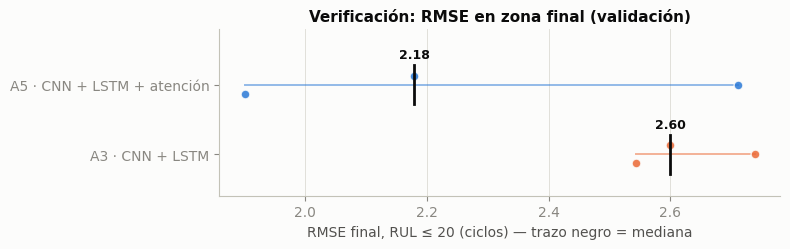

In [14]:
verif = run_many([dict(arch=a, seed=s) for a in ("A3", "A5") for s in (0, 1, 2)], label="  ")
verif_df = records_to_df(verif, "val")

if os.path.exists(V01_RESULTS) and not SMOKE_TEST:
    v01 = pd.read_csv(V01_RESULTS, encoding="utf-8-sig")
    v01_name = {"A3": "last", "A5": "attention"}
    rows = []
    for _, r in verif_df.iterrows():
        ref = v01[(v01["Brazo"] == v01_name[r["arch"]]) & (v01["Semilla"] == r["seed"])]["RMSE"].iloc[0]
        rows.append({"Arquitectura": r["arch"], "Semilla": r["seed"], "RMSE v01": ref,
                     "RMSE v02": r["RMSE"], "Diferencia": abs(ref - r["RMSE"])})
    comp = pd.DataFrame(rows)
    print(comp.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
    ok = comp["Diferencia"].max() < 1e-6
    print(f"\n{'OK: reproducción exacta de v01' if ok else 'ERROR: la infraestructura NO reproduce v01, revisar'}"
          f" (diferencia máxima {comp['Diferencia'].max():.2e})")
    assert ok

print("\nFormato de reporte (validación, 3 semillas solo para esta verificación):")
print(summary_table(verif_df, "arch").to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 2.6))
seed_dotplot(ax, verif_df, "RMSE final", ["A5", "A3"],
             labels={k: f"{k} · {ARCHS[k]['name']}" for k in ARCHS})
ax.set_title("Verificación: RMSE en zona final (validación)")
ax.set_xlabel("RMSE final, RUL ≤ 20 (ciclos) — trazo negro = mediana")
fig.tight_layout()
plt.show()

# Etapa 1 — Línea base y ablación de arquitecturas

**Pregunta:** ¿qué aporta cada bloque (convolución, recurrencia, atención) a la
estimación del RUL cerca del fallo? ¿Qué mecanismo de atención conviene llevar a las
etapas siguientes?

**Configuración:** las seis arquitecturas del catálogo (sección 0.8), con
normalización global, pérdida MSE y 5 semillas: 30 corridas. Las 6 corridas de A3 y
A5 con semillas 0–2 vienen de la verificación de la etapa 0.

**Criterio de selección (pre-registrado en la sección 0.13):** entre las
arquitecturas con atención (A4, A5, A6), pasa a las etapas 2 y 3 la de menor
**mediana de RMSE en la zona final** (RUL ≤ 20) en validación. A3 sigue como
referencia sin atención.

**Alcance:** esta etapa reporta solo **validación** (unidades 18 y 20). El conjunto de
prueba oficial se evalúa una única vez, al cierre de la etapa 4.

## 1.1 Entrenamiento

In [15]:
STAGE1_ARCHS = ["A1", "A2", "A3", "A4", "A5", "A6"]
ATT_ARCHS = ["A4", "A5", "A6"]
ARCH_LABELS = {k: f"{k} · {ARCHS[k]['name']}" for k in ARCHS}

stage1 = run_many([dict(arch=a, seed=s) for a in STAGE1_ARCHS for s in SEEDS], label="  ")
s1_val = records_to_df(stage1, "val")
s1_val.to_csv(os.path.join(OUT_DIR, "etapa1_val.csv"), index=False, encoding="utf-8-sig")

  A1 · global · α=1 · semilla 0 | mejor época  6/11 | caché
  A1 · global · α=1 · semilla 1 | mejor época  9/14 | caché
  A1 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A1 · global · α=1 · semilla 3 | mejor época  6/11 | caché
  A1 · global · α=1 · semilla 4 | mejor época  7/12 | caché
  A2 · global · α=1 · semilla 0 | mejor época  8/13 | caché
  A2 · global · α=1 · semilla 1 | mejor época  9/14 | caché
  A2 · global · α=1 · semilla 2 | mejor época 17/22 | caché
  A2 · global · α=1 · semilla 3 | mejor época  9/14 | caché
  A2 · global · α=1 · semilla 4 | mejor época  8/13 | caché
  A3 · global · α=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · α=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · α=1 · semilla 4 | mejor época 10/15 | caché
  A4 · global · α=1 · semilla 0 | mejor época  4/ 9 | caché
  A4 · global · α=1 · semilla 1 | mejor 

  A4 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A4 · global · α=1 · semilla 3 | mejor época  8/13 | caché
  A4 · global · α=1 · semilla 4 | mejor época  5/10 | caché
  A5 · global · α=1 · semilla 0 | mejor época 15/20 | caché
  A5 · global · α=1 · semilla 1 | mejor época 10/15 | caché
  A5 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A5 · global · α=1 · semilla 3 | mejor época  3/ 8 | caché
  A5 · global · α=1 · semilla 4 | mejor época  6/11 | caché
  A6 · global · α=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · α=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · α=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · α=1 · semilla 4 | mejor época 30/30 | caché
→ 30 corridas en 0.0 min (30 desde caché)


## 1.2 Resultados en validación

Primera tabla: mediana [mín. – máx.] sobre las 5 semillas, ordenada por la métrica
principal. Segunda tabla: el RMSE en la zona final de cada semilla, para ver la
dispersión completa. Tercera tabla: el RMSE en la zona final de cada unidad de
validación.

In [16]:
_order = s1_val.groupby("arch")["RMSE final"].median().sort_values().index.tolist()

tab1 = summary_table(s1_val, "arch", MAIN_METRICS + ["RMSE intermedia", "RMSE temprana"])
tab1 = tab1.set_index("arch").loc[_order].reset_index()
tab1.insert(1, "Arquitectura", tab1["arch"].map(lambda k: ARCHS[k]["name"]))
tab1.insert(2, "Parámetros", tab1["arch"].map(
    lambda k: f"{int(s1_val[s1_val['arch'] == k]['params'].iloc[0]):,}".replace(",", ".")))
print("Validación — mediana [mín. – máx.] sobre semillas, ordenado por RMSE final")
display(tab1.rename(columns={"arch": "Id"}))

print("\nRMSE en zona final por semilla (validación)")
display(s1_val.pivot(index="seed", columns="arch", values="RMSE final")[_order].round(3))

print("\nRMSE en zona final por unidad de validación — mediana [mín. – máx.]")
display(summary_table(s1_val, "arch", ["RMSE final u18", "RMSE final u20"])
        .set_index("arch").loc[_order].reset_index().rename(columns={"arch": "Id"}))

Validación — mediana [mín. – máx.] sobre semillas, ordenado por RMSE final


,Id,Arquitectura,Parámetros,n,RMSE final,Sobreest. media final,Score NASA final,RMSE,Sesgo,RMSE intermedia,RMSE temprana
0,A6,CNN + atención,14.497,5,2.00 [1.77 – 3.02],1.04 [0.80 – 1.48],0.18 [0.14 – 0.25],4.38 [4.35 – 4.91],-0.08 [-0.23 – 1.01],4.44 [3.88 – 5.28],5.75 [5.27 – 5.87]
1,A1,1D-CNN,10.273,5,2.02 [1.80 – 2.39],1.10 [0.91 – 1.24],0.16 [0.14 – 0.20],5.02 [4.80 – 5.53],1.56 [0.87 – 1.69],6.01 [5.16 – 6.29],5.85 [5.48 – 6.60]
2,A2,LSTM,23.617,5,2.07 [1.82 – 2.46],1.38 [0.87 – 1.87],0.18 [0.15 – 0.23],4.58 [4.48 – 4.78],0.91 [-0.06 – 1.89],4.77 [4.13 – 4.94],5.90 [5.53 – 6.05]
3,A4,LSTM + atención,27.841,5,2.17 [1.98 – 2.43],1.31 [1.16 – 1.76],0.18 [0.17 – 0.22],5.00 [4.80 – 5.17],1.78 [1.74 – 1.91],5.61 [5.30 – 5.96],6.01 [5.73 – 6.17]
4,A5,CNN + LSTM + atención,33.249,5,2.18 [1.90 – 2.78],1.52 [0.92 – 1.85],0.19 [0.15 – 0.24],4.89 [4.55 – 5.24],0.95 [0.37 – 2.18],5.60 [4.55 – 6.30],5.81 [5.44 – 6.04]
5,A3,CNN + LSTM,29.025,5,2.60 [2.26 – 2.74],1.89 [0.77 – 1.98],0.24 [0.18 – 0.25],4.93 [4.61 – 5.34],1.56 [0.72 – 1.91],5.55 [4.80 – 6.25],5.76 [5.63 – 6.14]



RMSE en zona final por semilla (validación)


arch,A6,A1,A2,A4,A5,A3
seed,,,,,,
0,2.004,2.016,2.071,2.168,1.901,2.543
1,3.019,1.870,2.149,2.394,2.711,2.738
2,1.781,1.801,2.456,2.425,2.179,2.599
3,1.772,2.316,2.015,1.982,2.779,2.614
4,2.202,2.391,1.823,2.139,2.154,2.262



RMSE en zona final por unidad de validación — mediana [mín. – máx.]


,Id,n,RMSE final u18,RMSE final u20
0,A6,5,1.47 [1.18 – 3.28],2.57 [1.92 – 2.80]
1,A1,5,1.55 [1.22 – 1.99],2.44 [2.18 – 2.90]
2,A2,5,1.43 [1.22 – 1.69],2.63 [1.97 – 3.23]
3,A4,5,1.47 [1.27 – 1.64],2.67 [2.52 – 3.21]
4,A5,5,1.84 [1.24 – 2.40],2.88 [2.17 – 3.37]
5,A3,5,1.93 [1.60 – 2.60],3.18 [2.49 – 3.47]


## 1.3 Selección del mecanismo de atención

Se aplica el criterio pre-registrado. Además se informa si el rango entre semillas de
la arquitectura elegida se solapa con el de A3: si se solapan, la ventaja de la
atención sobre la base sin atención no es nítida con 5 semillas, aunque la mediana
sea menor.

In [17]:
_med = s1_val.groupby("arch")["RMSE final"].median()
_rng = s1_val.groupby("arch")["RMSE final"].agg(["min", "max"])
STAGE1_CHOICE = _med[ATT_ARCHS].idxmin()

print("Ranking por mediana de RMSE final (validación):")
for i, k in enumerate(_order, 1):
    mark = "  (elegida)" if k == STAGE1_CHOICE else ("  (referencia sin atención)" if k == "A3" else "")
    print(f"  {i}. {ARCH_LABELS[k]:<28} {_med[k]:.3f}  [{_rng.loc[k, 'min']:.3f} – {_rng.loc[k, 'max']:.3f}]{mark}")

_overlap = not (_rng.loc[STAGE1_CHOICE, "max"] < _rng.loc["A3", "min"]
                or _rng.loc["A3", "max"] < _rng.loc[STAGE1_CHOICE, "min"])
_n_better = int((s1_val[s1_val["arch"] == STAGE1_CHOICE].set_index("seed")["RMSE final"]
                 < s1_val[s1_val["arch"] == "A3"].set_index("seed")["RMSE final"]).sum())
print(f"\nArquitectura elegida: {ARCH_LABELS[STAGE1_CHOICE]}")
print(f"Rango entre semillas solapado con A3: {'sí' if _overlap else 'no'}")
print(f"Semillas en que supera a A3 (misma semilla): {_n_better} de {len(SEEDS)}")

selection["decisiones"]["etapa_1"] = {
    "arquitectura_elegida": STAGE1_CHOICE,
    "nombre": ARCHS[STAGE1_CHOICE]["name"],
    "mediana_rmse_final_val": round(float(_med[STAGE1_CHOICE]), 4),
    "mediana_rmse_final_val_A3": round(float(_med["A3"]), 4),
    "rango_solapado_con_A3": bool(_overlap),
    "semillas_mejor_que_A3": _n_better,
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

Ranking por mediana de RMSE final (validación):
  1. A6 · CNN + atención          2.004  [1.772 – 3.019]  (elegida)
  2. A1 · 1D-CNN                  2.016  [1.801 – 2.391]
  3. A2 · LSTM                    2.071  [1.823 – 2.456]
  4. A4 · LSTM + atención         2.168  [1.982 – 2.425]
  5. A5 · CNN + LSTM + atención   2.179  [1.901 – 2.779]
  6. A3 · CNN + LSTM              2.599  [2.262 – 2.738]  (referencia sin atención)

Arquitectura elegida: A6 · CNN + atención
Rango entre semillas solapado con A3: sí
Semillas en que supera a A3 (misma semilla): 4 de 5


## 1.4 Figuras

### Comparación de arquitecturas

En los paneles a–c cada punto es una semilla, el trazo negro marca la mediana y la
línea horizontal, el rango. El panel d cruza el error con el número de parámetros:
sirve para distinguir el efecto de un bloque del efecto de tener más capacidad.

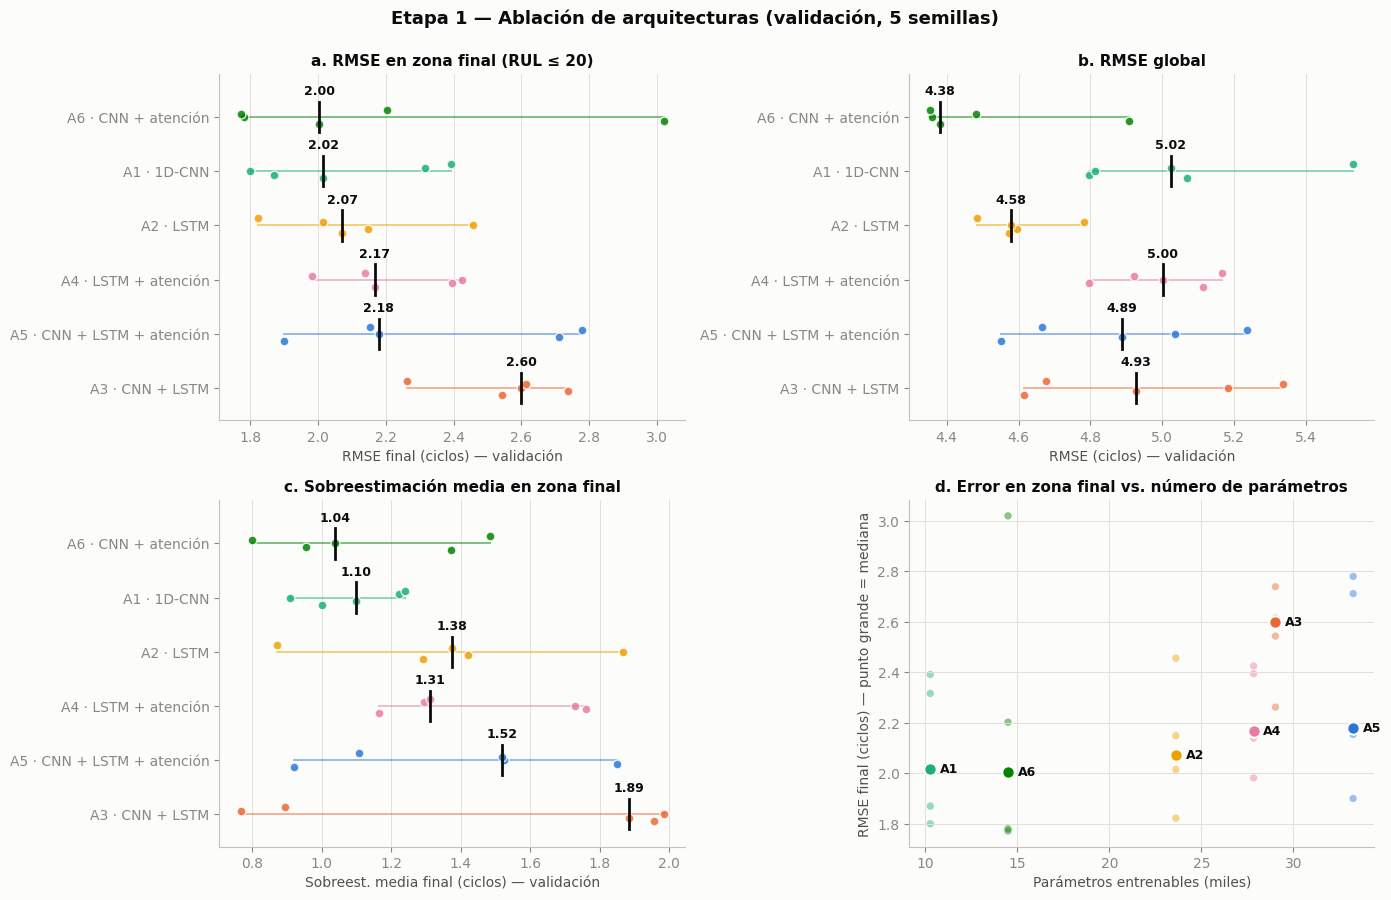

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric, title in (
        (axes[0, 0], "RMSE final", "a. RMSE en zona final (RUL ≤ 20)"),
        (axes[0, 1], "RMSE", "b. RMSE global"),
        (axes[1, 0], "Sobreest. media final", "c. Sobreestimación media en zona final")):
    seed_dotplot(ax, s1_val, metric, _order, labels=ARCH_LABELS)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} (ciclos) — validación")

ax = axes[1, 1]
for k in _order:
    sub = s1_val[s1_val["arch"] == k]
    ax.scatter(sub["params"] / 1000, sub["RMSE final"], s=28, color=ARCH_COLORS[k], alpha=0.45,
               edgecolor="none")
    ax.scatter(sub["params"].iloc[0] / 1000, sub["RMSE final"].median(), s=80, color=ARCH_COLORS[k],
               edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(k, (sub["params"].iloc[0] / 1000, sub["RMSE final"].median()), xytext=(7, 0),
                textcoords="offset points", va="center", color=INK, fontsize=9, fontweight="bold")
ax.set_title("d. Error en zona final vs. número de parámetros")
ax.set_xlabel("Parámetros entrenables (miles)")
ax.set_ylabel("RMSE final (ciclos) — punto grande = mediana")

fig.suptitle("Etapa 1 — Ablación de arquitecturas (validación, 5 semillas)",
             fontsize=13, fontweight="bold", color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_ablacion.png"), dpi=160, bbox_inches="tight")
plt.show()

### Curvas de aprendizaje

RMSE de validación por época. Cada línea tenue es una semilla y la línea gruesa es la
mediana punto a punto, calculada hasta la época en que terminó la corrida más corta.

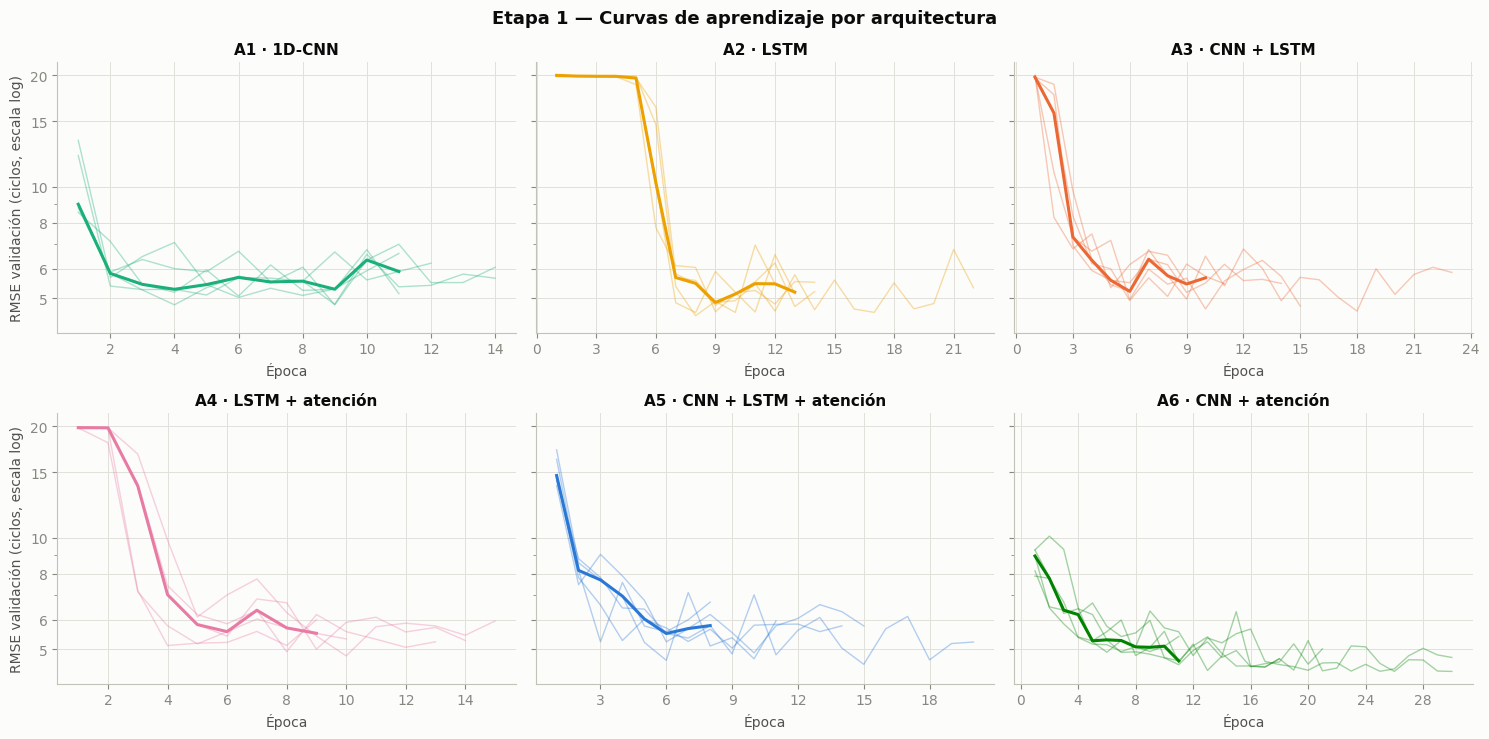

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
by_arch = {k: [r for r in stage1 if r["arch"] == k] for k in STAGE1_ARCHS}
for ax, k in zip(axes.ravel(), STAGE1_ARCHS):
    seed_curves(ax, by_arch[k], "val_rmse", color=ARCH_COLORS[k])
    ax.set_title(ARCH_LABELS[k])
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.FixedLocator([4, 5, 6, 8, 10, 15, 20, 30]))
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.set_xlabel("Época")
for ax in axes[:, 0]:
    ax.set_ylabel("RMSE validación (ciclos, escala log)")
fig.suptitle("Etapa 1 — Curvas de aprendizaje por arquitectura",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_curvas.png"), dpi=160, bbox_inches="tight")
plt.show()

### Trayectorias de RUL en las unidades de validación

Para cada ciclo de vuelo se promedian las ventanas del ciclo y luego se toma la mediana
entre semillas. Se comparan la línea base simple (A1), la base híbrida sin atención
(A3) y la arquitectura elegida. La franja sombreada es la zona final.

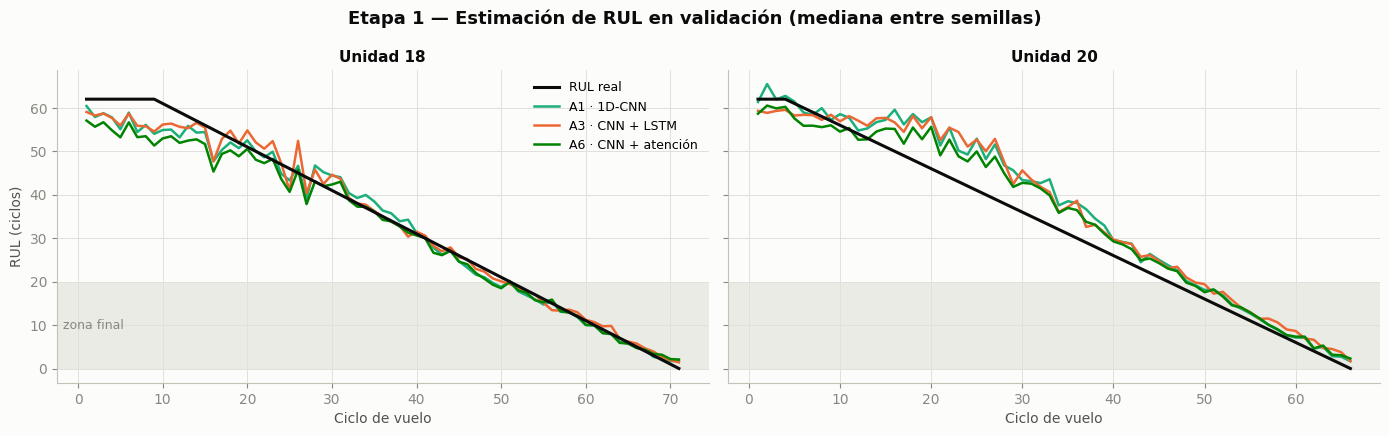

In [20]:
_, _yv, _mv = build_tensors("global", "oficial")["val"]
_show = list(dict.fromkeys(["A1", "A3", STAGE1_CHOICE]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, u in zip(axes, VAL_UNITS):
    m = _mv[:, 0] == u
    cyc = np.unique(_mv[m, 1])
    true_c = [_yv[m][_mv[m, 1] == c].mean() for c in cyc]
    ax.axhspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.plot(cyc, true_c, color=INK, lw=2.2, label="RUL real", zorder=4)
    for k in _show:
        per_seed = [[r["val_pred"][m][_mv[m, 1] == c].mean() for c in cyc] for r in by_arch[k]]
        ax.plot(cyc, np.median(per_seed, axis=0), color=ARCH_COLORS[k], lw=1.8,
                label=ARCH_LABELS[k], zorder=3)
    ax.set_title(f"Unidad {int(u)}")
    ax.set_xlabel("Ciclo de vuelo")
axes[0].set_ylabel("RUL (ciclos)")
axes[0].annotate("zona final", (0.01, FINAL_ZONE / 2), xycoords=("axes fraction", "data"),
                 color=MUTED, fontsize=9, va="center")
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 1 — Estimación de RUL en validación (mediana entre semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

### Pesos de atención (criterio C8, interpretabilidad)

Peso promedio $\alpha_t$ asignado a cada paso de la ventana, en validación y promediado
sobre las semillas, separando las ventanas de la zona final del resto. Un perfil plano
sobre $1/30$ indicaría que la atención actúa como un promedio simple; un perfil que
cambia entre zonas indica que el modelo atiende a instantes distintos según la etapa
de degradación.

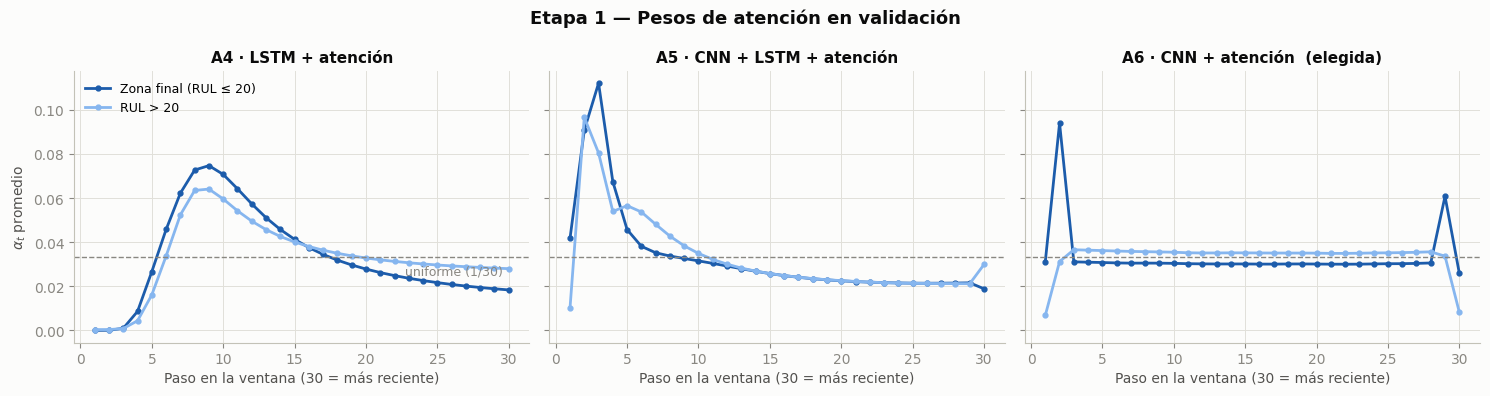

In [21]:
_Xv = build_tensors("global", "oficial")["val"][0]
_fin = _yv <= FINAL_ZONE
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
steps = np.arange(1, WINDOW_SIZE + 1)
for ax, k in zip(axes, ATT_ARCHS):
    W = np.mean([predict(load_model(r), _Xv, collect_weights=True)[1] for r in by_arch[k]], axis=0)
    ax.plot(steps, W[_fin].mean(axis=0), color="#1c5cab", lw=2, marker="o", ms=3.5,
            label=f"Zona final (RUL ≤ {FINAL_ZONE:g})")
    ax.plot(steps, W[~_fin].mean(axis=0), color="#86b6ef", lw=2, marker="o", ms=3.5,
            label=f"RUL > {FINAL_ZONE:g}")
    ax.axhline(1 / WINDOW_SIZE, color=MUTED, lw=1, ls="--")
    ax.set_title(ARCH_LABELS[k] + ("  (elegida)" if k == STAGE1_CHOICE else ""))
    ax.set_xlabel("Paso en la ventana (30 = más reciente)")
axes[0].set_ylabel(r"$\alpha_t$ promedio")
axes[0].annotate("uniforme (1/30)", (WINDOW_SIZE, 1 / WINDOW_SIZE), xytext=(-4, -13),
                 textcoords="offset points", ha="right", color=MUTED, fontsize=9)
axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Etapa 1 — Pesos de atención en validación", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa1_atencion.png"), dpi=160, bbox_inches="tight")
plt.show()

## 1.5 Discusión

### Cinco de las seis arquitecturas son indistinguibles en la zona final

| Id | Arquitectura | Parámetros | RMSE final (validación) |
|---|---|---|---|
| A6 | CNN + atención | 14.497 | 2,00 [1,77 – 3,02] |
| A1 | 1D-CNN | 10.273 | 2,02 [1,80 – 2,39] |
| A2 | LSTM | 23.617 | 2,07 [1,82 – 2,46] |
| A4 | LSTM + atención | 27.841 | 2,17 [1,98 – 2,43] |
| A5 | CNN + LSTM + atención | 33.249 | 2,18 [1,90 – 2,78] |
| A3 | CNN + LSTM | 29.025 | 2,60 [2,26 – 2,74] |

Las medianas de A6, A1, A2, A4 y A5 caben en 0,18 ciclos y sus rangos se solapan
ampliamente. Con 5 semillas no es posible ordenarlas. La única arquitectura que se
separa es **A3, y lo hace hacia peor**: su mejor semilla (2,26) es peor que la mediana
de todas las demás. Es la base híbrida sin atención de v01.

### El efecto de la atención depende de la arquitectura base

Comparando cada arquitectura con su versión con atención:

| Par | RMSE final | RMSE global | Sesgo |
|---|---|---|---|
| CNN → CNN + atención (A1 → A6) | 2,02 → 2,00 | 5,02 → 4,38 | +1,56 → −0,08 |
| LSTM → LSTM + atención (A2 → A4) | 2,07 → 2,17 | 4,58 → 5,00 | +0,91 → +1,78 |
| CNN + LSTM → con atención (A3 → A5) | 2,60 → 2,18 | 4,93 → 4,89 | +1,56 → +0,95 |

La atención mejora la zona final solo sobre CNN + LSTM (A5 supera a A3 en 4 de 5
semillas). Sobre la CNN no cambia la zona final, aunque mejora el error global y casi
elimina el sesgo. Sobre la LSTM empeora levemente ambas métricas. **No hay un beneficio
uniforme de la atención en este problema.**

### Más parámetros no implican menos error

El panel d no muestra relación entre capacidad y error en la zona final. A1, la
arquitectura más simple (10 mil parámetros), empata con las mejores; A5, la de mayor
capacidad (33 mil), queda en quinto lugar. Las diferencias observadas no se explican por
el tamaño del modelo.

### Los pesos de atención de A6 son casi uniformes

En A6 los pesos se mantienen en torno a $1/30$ en casi toda la ventana, con picos solo
en los pasos 2 y 29. Esos picos coinciden con los bordes donde las dos convoluciones
(kernel 3) actúan sobre el relleno de ceros, por lo que probablemente reflejan un
efecto de borde y no una selección de instantes con significado físico. En la práctica,
**A6 se comporta como un promedio temporal**, lo que explica que empate con A1, que
promedia explícitamente.

A4 y A5 sí muestran perfiles no uniformes: A4 concentra el peso en los pasos 7–10, con
un pico más marcado en la zona final; A5 concentra el peso en los primeros pasos de la
ventana. Para el criterio C8 (interpretabilidad), A4 y A5 son más informativas que A6.

### Selección

Aplicando el criterio pre-registrado, **A6 (CNN + atención) pasa a las etapas 2 y 3**,
con A3 como referencia sin atención. Hay cuatro salvedades que deben quedar declaradas:

1. Su ventaja sobre A1 es de 0,01 ciclos, sin relevancia práctica.
2. Tiene el rango más amplio entre semillas, por una semilla atípica (3,02).
3. Su atención es casi uniforme, por lo que aporta poca interpretabilidad.
4. En una semilla alcanzó el límite de 30 épocas sin activar el early stopping, y en
   otra se detuvo justo en ese límite. Su resultado podría estar **subestimado** por un
   entrenamiento incompleto, no sobreestimado.

Frente a A3, el rango de A6 se solapa, pero A6 es mejor en 4 de las 5 semillas.

### Implicancia para el trabajo

En DS02, la arquitectura híbrida completa (A5, la alternativa seleccionada en la etapa
de diseño) no supera en la zona final a modelos más simples. El aporte del trabajo está
en el análisis: qué bloque aporta qué, cuándo ayuda la atención y qué muestran sus
pesos. Esto calza con lo que el profesor planteó en la Reunión 03, que el análisis es la
contribución principal.

# Etapa 2 — Normalización por condición de operación

**Pregunta:** ¿mejora la estimación cerca del fallo si los sensores se normalizan
según la condición de operación, en vez de con una única estandarización global?

**Por qué no se normaliza literalmente por `Fc`.** Como se vio en la sección 0.4, `Fc`
es constante por motor y todas las unidades de `dev` son `Fc = 3`. En entrenamiento,
normalizar por `Fc` sería idéntico a la normalización global, y para las unidades de
prueba 14 y 15 (`Fc` 1 y 2) no habría estadísticas con que normalizar. Se comparan en
cambio dos métodos que capturan la condición de operación de forma aplicable a
cualquier motor:

| Id | Método | Qué elimina | Qué aprende de entrenamiento |
|---|---|---|---|
| global | Estandarización de los 18 canales (v01, etapa 1) | Escala de cada canal | Media y desviación de cada canal |
| **N1a** `regimen` | Regímenes de operación: k-means sobre W; cada sensor se estandariza con la media y desviación de su régimen | La variación de los sensores debida al punto de operación (altitud, Mach, empuje, temperatura) | Los regímenes y las estadísticas por régimen |
| **N1b** `motor` | Línea base por motor: cada sensor se estandariza con la media y desviación de los primeros 10 ciclos del propio motor | El nivel propio de cada motor, incluido el efecto de su perfil de vuelo | Nada de los sensores (solo la escala de W) |

En los tres métodos las 4 condiciones W se estandarizan globalmente y siguen siendo
entrada del modelo, de modo que la red siempre "ve" la condición de operación.

**Sobre N1b en operación real.** Usa datos del propio motor evaluado, pero solo de sus
primeros 10 ciclos, que son sanos en todas las unidades (la transición más temprana
ocurre en el ciclo 16), y sin usar etiquetas. Es lo que se tendría en la práctica: un
motor nuevo vuela algunos ciclos antes de que se le pida un pronóstico.

**Configuración:** la arquitectura elegida en la etapa 1 y A3 como referencia, con las
tres normalizaciones, MSE y 5 semillas. Las corridas con normalización global ya
existen desde la etapa 1.

**Criterio (pre-registrado en la sección 0.13):** se adopta la normalización con
menor mediana de RMSE en la zona final en validación para la arquitectura elegida. Si
ninguna de las nuevas mejora a la global, se mantiene la global.

## 2.1 Implementación de las normalizaciones

Ambas se registran en `NORMALIZERS`, igual que la global. Como `build_tensors`
reajusta la normalización para cada partición, en la validación cruzada de la etapa 4
los regímenes y estadísticas se volverán a aprender en cada fold, sin fuga.

El número de regímenes K de N1a se elige con el coeficiente de silueta sobre una
submuestra de los registros de entrenamiento.

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

N_W = len(var_names["W"])          # las primeras 4 columnas son W; el resto, sensores X_s
REGIME_K_RANGE = range(2, 7)       # candidatos para el número de regímenes
BASELINE_CYCLES = 10               # ciclos iniciales que definen la línea base de cada motor
NORM_INFO = {}                     # diagnóstico del último ajuste de cada método

NORM_TAGS["regimen"] = f"regimen{REGIME_K_RANGE.start}-{REGIME_K_RANGE.stop - 1}"
NORM_TAGS["motor"] = f"motor{BASELINE_CYCLES}"
NORM_LABELS = {"global": "global", "regimen": "N1a régimen", "motor": "N1b motor"}


def _fit_regimen(d, train_mask):
    F_tr = d["features"][train_mask]
    channel_scaler = StandardScaler().fit(F_tr)              # escala global para W
    w_scaler = StandardScaler().fit(F_tr[:, :N_W])
    Wz = w_scaler.transform(F_tr[:, :N_W])

    sub = np.random.default_rng(0).choice(len(Wz), size=min(20000, len(Wz)), replace=False)
    scores = {}
    for k in REGIME_K_RANGE:
        labels_k = KMeans(k, n_init=10, random_state=0).fit_predict(Wz[sub])
        scores[k] = float(silhouette_score(Wz[sub], labels_k, sample_size=5000, random_state=0))
    k_best = max(scores, key=scores.get)
    km = KMeans(k_best, n_init=10, random_state=0).fit(Wz)

    S_tr = F_tr[:, N_W:]
    mu = np.stack([S_tr[km.labels_ == c].mean(axis=0) for c in range(k_best)])
    sd = np.stack([S_tr[km.labels_ == c].std(axis=0) for c in range(k_best)]) + 1e-6
    NORM_INFO["regimen"] = {"k": k_best, "silueta": scores, "km": km, "w_scaler": w_scaler,
                            "proporcion": np.bincount(km.labels_, minlength=k_best) / len(km.labels_)}

    def transform(dd):
        F = dd["features"]
        out = channel_scaler.transform(F).astype(np.float32)
        lab = km.predict(w_scaler.transform(F[:, :N_W]))
        out[:, N_W:] = (F[:, N_W:] - mu[lab]) / sd[lab]
        return out.astype(np.float32)
    return transform


def _fit_motor(d, train_mask):
    channel_scaler = StandardScaler().fit(d["features"][train_mask])   # escala global para W

    def transform(dd):
        F = dd["features"]
        out = channel_scaler.transform(F).astype(np.float32)
        for u in np.unique(dd["unit"]):
            m = dd["unit"] == u
            base = m & (dd["cycle"] <= BASELINE_CYCLES)
            mu, sd = F[base, N_W:].mean(axis=0), F[base, N_W:].std(axis=0) + 1e-6
            out[m, N_W:] = (F[m, N_W:] - mu) / sd
        return out.astype(np.float32)
    return transform


NORMALIZERS["regimen"] = _fit_regimen
NORMALIZERS["motor"] = _fit_motor

# Los primeros ciclos de cada motor deben ser sanos para que N1b sea una línea base válida
for split_name, d in (("dev", dev), ("test", test)):
    for u in np.unique(d["unit"]):
        m = (d["unit"] == u) & (d["cycle"] <= BASELINE_CYCLES)
        assert np.all(d["hs"][m] == 1), f"unidad {u}: hay ciclos degradados en la línea base"
print(f"OK: los primeros {BASELINE_CYCLES} ciclos de las 9 unidades son sanos (hs = 1).")

OK: los primeros 10 ciclos de las 9 unidades son sanos (hs = 1).


## 2.2 Regímenes de operación (N1a)

Coeficiente de silueta por K (submuestra de entrenamiento):
   K = 2: 0.506  (elegido)
   K = 3: 0.381
   K = 4: 0.376
   K = 5: 0.396
   K = 6: 0.396

Proporción de registros de entrenamiento por régimen: R1 60.2 %, R2 39.8 %

Centro de cada régimen:
             alt  Mach        TRA          T2
R1  26245.339844  0.68  74.750000  463.880005
R2  15123.860352  0.54  58.860001  492.230011


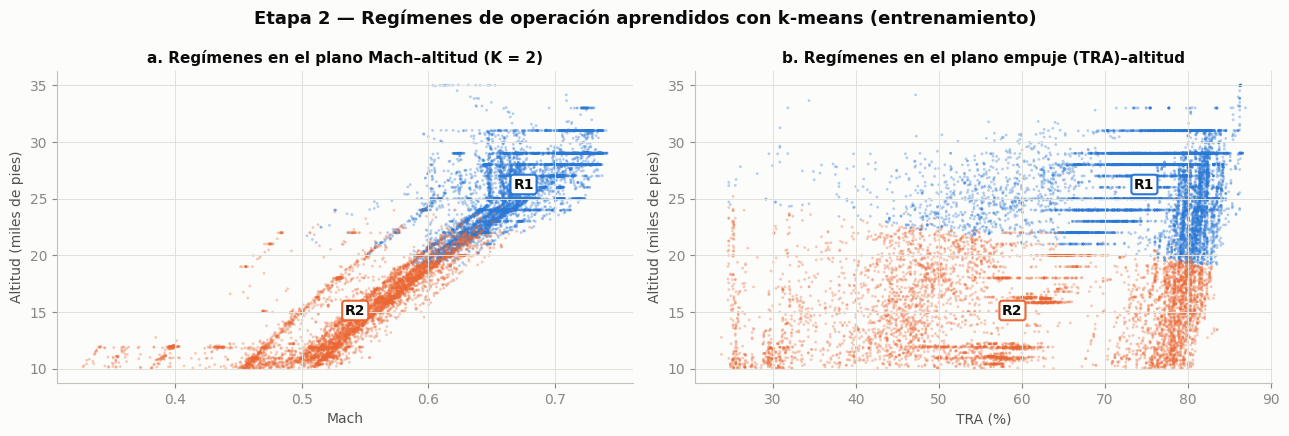

In [23]:
_tr_mask = np.isin(dev["unit"], TRAIN_UNITS)
NORM_TRANSFORMS = {n: fit_normalizer(n, dev, _tr_mask) for n in ("global", "regimen", "motor")}
info = NORM_INFO["regimen"]
print("Coeficiente de silueta por K (submuestra de entrenamiento):")
for k, s in info["silueta"].items():
    print(f"   K = {k}: {s:.3f}{'  (elegido)' if k == info['k'] else ''}")
print(f"\nProporción de registros de entrenamiento por régimen: "
      f"{', '.join(f'R{c + 1} {100 * p:.1f} %' for c, p in enumerate(info['proporcion']))}")

centers = info["w_scaler"].inverse_transform(info["km"].cluster_centers_)
print("\nCentro de cada régimen:")
print(pd.DataFrame(centers, columns=var_names["W"],
                   index=[f"R{c + 1}" for c in range(info["k"])]).round(2).to_string())

_REG_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
_sub = np.random.default_rng(1).choice(np.where(_tr_mask)[0], size=15000, replace=False)
_lab = info["km"].predict(info["w_scaler"].transform(dev["features"][_sub, :N_W]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (xi, yi) in zip(axes, ((1, 0), (2, 0))):
    for c in range(info["k"]):
        mm = _lab == c
        ax.scatter(dev["features"][_sub[mm], xi], dev["features"][_sub[mm], yi] / 1000, s=4,
                   color=_REG_COLORS[c], alpha=0.35, edgecolor="none")
        ax.annotate(f"R{c + 1}", (centers[c, xi], centers[c, yi] / 1000), ha="center", va="center",
                    fontsize=10, fontweight="bold", color=INK,
                    bbox=dict(boxstyle="round,pad=0.2", fc=SURFACE, ec=_REG_COLORS[c], lw=1.5))
    ax.set_xlabel(var_names["W"][xi] + (" (%)" if var_names["W"][xi] == "TRA" else ""))
    ax.set_ylabel("Altitud (miles de pies)")
axes[0].set_title(f"a. Regímenes en el plano Mach–altitud (K = {info['k']})")
axes[1].set_title("b. Regímenes en el plano empuje (TRA)–altitud")
fig.suptitle("Etapa 2 — Regímenes de operación aprendidos con k-means (entrenamiento)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa2_regimenes.png"), dpi=160, bbox_inches="tight")
plt.show()

## 2.3 Qué hace cada normalización sobre un sensor

T48 (temperatura a la salida de la turbina de alta presión) responde a la degradación
HPT, el modo de falla común a todas las unidades. La figura sigue T48 a lo largo de un
vuelo completo de la unidad 18 (ciclo 5, motor sano), con la altitud y el régimen
asignado en el panel superior.

Los dos métodos actúan a escalas distintas:

- **N1a actúa dentro del vuelo.** Al pasar de un régimen a otro, resta la media de
  ese régimen. En principio, esto reduce la parte de la variación de T48 que se debe
  solo al punto de operación (ascenso, crucero, descenso). Cuánto lo logra depende del
  número de regímenes; se analiza en la sección 2.7.
- **N1b actúa entre motores.** Aplica una sola media y desviación a todo el motor, así
  que dentro de un vuelo conserva exactamente la forma de la normalización global;
  solo la desplaza y reescala. Su efecto es alinear motores cuyo nivel base difiere,
  por ejemplo por volar perfiles distintos.

Solo se usan unidades de `dev`: el conjunto de prueba no participa en ninguna
decisión de esta etapa.

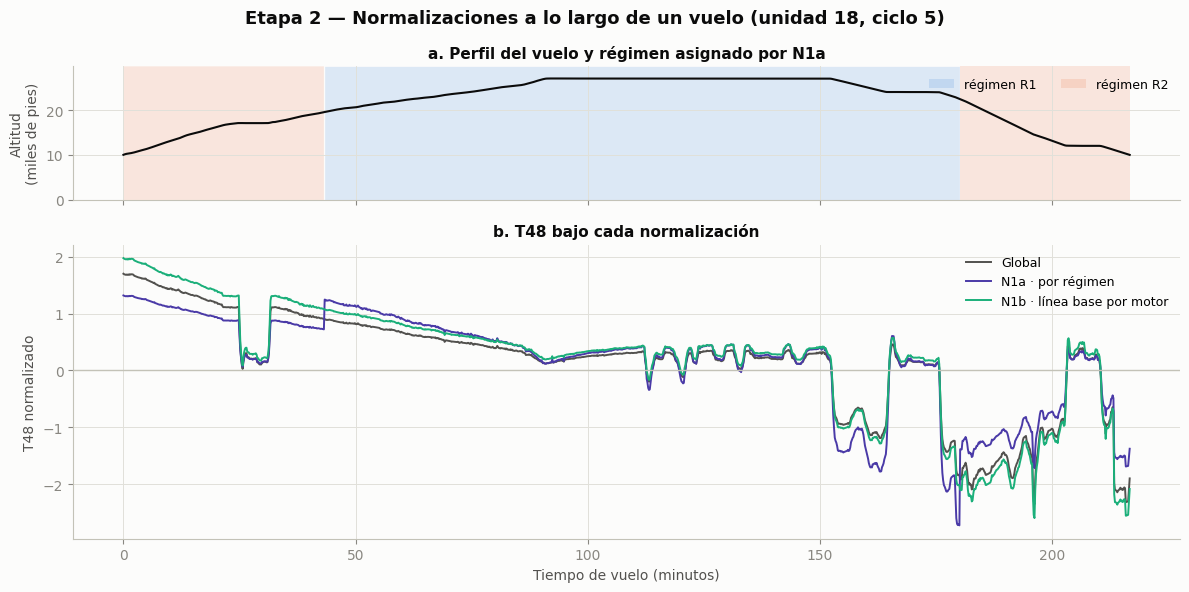

Fracción de la varianza de los sensores explicada linealmente por W (R², mediana [mín. – máx.] sobre los 14 sensores, entrenamiento):


   global       0.99 [0.98 – 1.00]


   N1a régimen  0.84 [0.38 – 0.91]


   N1b motor    0.98 [0.97 – 0.99]


In [24]:
_s = FEATURE_NAMES.index("T48")
_m = (dev["unit"] == 18) & (dev["cycle"] == 5)
_t = np.arange(_m.sum()) * SAMPLE_STEP / 60                        # minutos de vuelo
_lab = info["km"].predict(info["w_scaler"].transform(dev["features"][_m, :N_W]))
NORM_COLORS = {"global": INK_2, "regimen": "#4a3aa7", "motor": "#1baf7a"}

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2.2]})
alt = dev["features"][_m, 0] / 1000
for c in range(info["k"]):
    ax0.fill_between(_t, 0, alt.max() * 1.1, where=_lab == c, color=_REG_COLORS[c],
                     alpha=0.15, lw=0, step="mid", label=f"régimen R{c + 1}")
ax0.plot(_t, alt, color=INK, lw=1.5)
ax0.set_ylim(0, alt.max() * 1.1)
ax0.set_ylabel("Altitud\n(miles de pies)")
ax0.legend(loc="upper right", fontsize=9, ncol=info["k"])
ax0.set_title("a. Perfil del vuelo y régimen asignado por N1a")

for n in ("global", "regimen", "motor"):
    ax1.plot(_t, NORM_TRANSFORMS[n](dev)[_m, _s], color=NORM_COLORS[n], lw=1.4,
             label={"global": "Global", "regimen": "N1a · por régimen",
                    "motor": "N1b · línea base por motor"}[n])
ax1.axhline(0, color=AXIS, lw=1)
ax1.set_ylabel("T48 normalizado")
ax1.set_xlabel("Tiempo de vuelo (minutos)")
ax1.set_title("b. T48 bajo cada normalización")
ax1.legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 2 — Normalizaciones a lo largo de un vuelo (unidad 18, ciclo 5)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa2_sensor_T48.png"), dpi=160, bbox_inches="tight")
plt.show()

# Cuánto de la varianza de cada sensor explica la condición de operación W (R² lineal),
# en entrenamiento, bajo cada normalización
from sklearn.linear_model import LinearRegression
_W_tr = dev["features"][_tr_mask, :N_W]
print("Fracción de la varianza de los sensores explicada linealmente por W "
      "(R², mediana [mín. – máx.] sobre los 14 sensores, entrenamiento):")
for n in ("global", "regimen", "motor"):
    S = NORM_TRANSFORMS[n](dev)[_tr_mask, N_W:]
    r2 = [LinearRegression().fit(_W_tr, S[:, j]).score(_W_tr, S[:, j]) for j in range(S.shape[1])]
    print(f"   {NORM_LABELS[n]:<12} {med_range(r2)}")

## 2.4 Entrenamiento

In [25]:
STAGE2_ARCHS = list(dict.fromkeys([STAGE1_CHOICE, "A3"]))
STAGE2_NORMS = ["global", "regimen", "motor"]

stage2 = run_many([dict(arch=a, norm=n, seed=s) for a in STAGE2_ARCHS for n in STAGE2_NORMS
                   for s in SEEDS], label="  ")
s2_val = records_to_df(stage2, "val")
s2_val["cfg"] = s2_val["arch"] + " · " + s2_val["norm"].map(NORM_LABELS)
s2_val.to_csv(os.path.join(OUT_DIR, "etapa2_val.csv"), index=False, encoding="utf-8-sig")

  A6 · global · α=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · α=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · α=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · α=1 · semilla 4 | mejor época 30/30 | caché


  A6 · regimen · α=1 · semilla 0 | mejor época  7/12 | caché
  A6 · regimen · α=1 · semilla 1 | mejor época  7/12 | caché
  A6 · regimen · α=1 · semilla 2 | mejor época 14/19 | caché
  A6 · regimen · α=1 · semilla 3 | mejor época 18/23 | caché
  A6 · regimen · α=1 · semilla 4 | mejor época 19/24 | caché


  A6 · motor · α=1 · semilla 0 | mejor época  6/11 | caché
  A6 · motor · α=1 · semilla 1 | mejor época  7/12 | caché
  A6 · motor · α=1 · semilla 2 | mejor época  6/11 | caché
  A6 · motor · α=1 · semilla 3 | mejor época  5/10 | caché
  A6 · motor · α=1 · semilla 4 | mejor época  4/ 9 | caché
  A3 · global · α=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · α=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · α=1 · semilla 4 | mejor época 10/15 | caché
  A3 · regimen · α=1 · semilla 0 | mejor época  6/11 | caché
  A3 · regimen · α=1 · semilla 1 | mejor época  4/ 9 | caché
  A3 · regimen · α=1 · semilla 2 | mejor época  4/ 9 | caché
  A3 · regimen · α=1 · semilla 3 | mejor época 11/16 | caché
  A3 · regimen · α=1 · semilla 4 | mejor época  9/14 | caché
  A3 · motor · α=1 · semilla 0 | mejor época  9/14 | caché
  A3 · motor · α=1 · semilla 1 | mejor ép

  A3 · motor · α=1 · semilla 4 | mejor época  8/13 | caché
→ 30 corridas en 0.1 min (30 desde caché)


## 2.5 Resultados en validación y selección

In [26]:
print("Validación — mediana [mín. – máx.] sobre semillas")
display(summary_table(s2_val, ["arch", "norm"],
                      MAIN_METRICS + ["RMSE final u18", "RMSE final u20"]))

print("\nRMSE en zona final por semilla (validación)")
display(s2_val.pivot_table(index="seed", columns=["arch", "norm"], values="RMSE final").round(3))

_m2 = s2_val[s2_val["arch"] == STAGE1_CHOICE].groupby("norm")["RMSE final"].median()
STAGE2_CHOICE = _m2.idxmin() if _m2.drop("global").min() < _m2["global"] else "global"

print(f"\nMediana de RMSE final para {ARCH_LABELS[STAGE1_CHOICE]}:")
_g = s2_val[(s2_val["arch"] == STAGE1_CHOICE) & (s2_val["norm"] == "global")].set_index("seed")["RMSE final"]
for n in STAGE2_NORMS:
    v = s2_val[(s2_val["arch"] == STAGE1_CHOICE) & (s2_val["norm"] == n)].set_index("seed")["RMSE final"]
    better = "" if n == "global" else f" | mejor que global en {int((v < _g).sum())} de {len(SEEDS)} semillas"
    print(f"   {NORM_LABELS[n]:<12} {_m2[n]:.3f}{better}{'  (elegida)' if n == STAGE2_CHOICE else ''}")

selection["decisiones"]["etapa_2"] = {
    "normalizacion_elegida": STAGE2_CHOICE,
    "arquitectura": STAGE1_CHOICE,
    "mediana_rmse_final_val": {n: round(float(_m2[n]), 4) for n in STAGE2_NORMS},
    "regimenes_K": int(NORM_INFO["regimen"]["k"]) if "regimen" in NORM_INFO else None,
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

Validación — mediana [mín. – máx.] sobre semillas


,arch,norm,n,RMSE final,Sobreest. media final,Score NASA final,RMSE,Sesgo,RMSE final u18,RMSE final u20
0,A6,global,5,2.00 [1.77 – 3.02],1.04 [0.80 – 1.48],0.18 [0.14 – 0.25],4.38 [4.35 – 4.91],-0.08 [-0.23 – 1.01],1.47 [1.18 – 3.28],2.57 [1.92 – 2.80]
1,A6,regimen,5,2.02 [1.84 – 2.43],1.12 [0.77 – 1.23],0.17 [0.15 – 0.19],4.57 [4.41 – 4.83],0.05 [-0.24 – 1.13],1.40 [1.21 – 2.63],2.41 [2.18 – 2.55]
2,A6,motor,5,3.29 [2.90 – 4.06],0.93 [0.75 – 1.38],0.28 [0.23 – 0.36],7.58 [6.81 – 7.91],-3.21 [-4.28 – -1.09],3.74 [3.25 – 4.68],2.70 [2.10 – 3.78]
3,A3,global,5,2.60 [2.26 – 2.74],1.89 [0.77 – 1.98],0.24 [0.18 – 0.25],4.93 [4.61 – 5.34],1.56 [0.72 – 1.91],1.93 [1.60 – 2.60],3.18 [2.49 – 3.47]
4,A3,regimen,5,2.35 [2.11 – 2.96],1.59 [1.32 – 1.94],0.21 [0.19 – 0.27],5.22 [5.05 – 5.48],1.94 [1.35 – 2.35],1.73 [1.34 – 2.20],3.12 [2.57 – 3.62]
5,A3,motor,5,3.96 [3.71 – 4.88],2.15 [1.60 – 2.36],0.38 [0.35 – 0.52],6.78 [6.55 – 7.50],-0.74 [-1.71 – 0.27],3.57 [3.32 – 4.77],4.22 [3.70 – 4.99]



RMSE en zona final por semilla (validación)


arch     A3                    A6               
norm global  motor regimen global  motor regimen
seed                                            
0     2.543  3.775   2.115  2.004  2.899   2.166
1     2.738  3.958   2.307  3.019  3.777   2.429
2     2.599  3.714   2.959  1.781  4.056   2.023
3     2.614  4.878   2.725  1.772  3.288   1.838
4     2.262  4.007   2.353  2.202  3.278   1.938


Mediana de RMSE final para A6 · CNN + atención:
   global       2.004  (elegida)
   N1a régimen  2.023 | mejor que global en 2 de 5 semillas
   N1b motor    3.288 | mejor que global en 0 de 5 semillas


## 2.6 Figuras

Cada punto es una semilla; el trazo negro marca la mediana. Las filas de una misma
arquitectura comparten color.

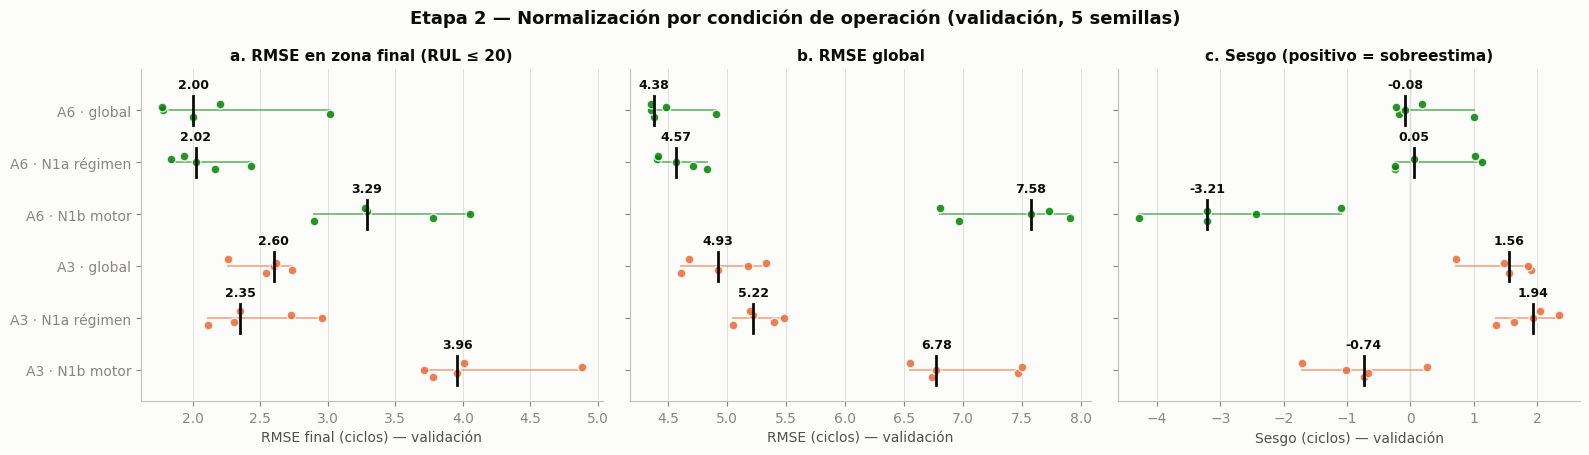

In [27]:
_cfgs = [f"{a} · {NORM_LABELS[n]}" for a in STAGE2_ARCHS for n in STAGE2_NORMS]
_cfg_colors = {c: ARCH_COLORS[c.split(" · ")[0]] for c in _cfgs}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, metric, title in ((axes[0], "RMSE final", "a. RMSE en zona final (RUL ≤ 20)"),
                          (axes[1], "RMSE", "b. RMSE global"),
                          (axes[2], "Sesgo", "c. Sesgo (positivo = sobreestima)")):
    seed_dotplot(ax, s2_val, metric, _cfgs, group_col="cfg", colors=_cfg_colors)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} (ciclos) — validación")
axes[2].axvline(0, color=AXIS, lw=1, zorder=1)
fig.suptitle("Etapa 2 — Normalización por condición de operación (validación, 5 semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa2_normalizacion.png"), dpi=160, bbox_inches="tight")
plt.show()

## 2.7 Discusión

### Resultados en validación (RMSE en zona final)

| Normalización | A6 · CNN + atención | A3 · CNN + LSTM |
|---|---|---|
| Global | **2,00** [1,77 – 3,02] | 2,60 [2,26 – 2,74] |
| N1a · régimen | 2,02 [1,84 – 2,43] | **2,35** [2,11 – 2,96] |
| N1b · motor | 3,29 [2,90 – 4,06] | 3,96 [3,71 – 4,88] |

### Selección: se mantiene la normalización global

Aplicando el criterio pre-registrado, ninguna normalización nueva reduce la mediana de
A6, así que **las etapas siguientes usan la normalización global**. La diferencia con
N1a es de 0,02 ciclos, un empate: N1a mejora a A6 solo en 2 de 5 semillas.

### N1a: efecto pequeño y dependiente de la arquitectura

- **Sobre A3 mejora la mediana** (2,60 → 2,35), pero los rangos se solapan.
- **Sobre A6 no cambia la mediana, pero estrecha el rango** (peor semilla: 3,02 → 2,43)
  y mejora levemente el score NASA final (0,18 → 0,17). Es decir, da un entrenamiento
  algo más estable.
- **Su alcance está limitado por el número de regímenes.** La silueta eligió K = 2
  (crucero alto frente a ascenso y descenso), con lo que la parte de la varianza de los
  sensores explicada por W baja solo del 99 % al 84 %. Además, la asignación tajante a
  un régimen introduce un escalón artificial en la frontera (figura de la sección 2.3,
  minuto 43). Un número mayor de regímenes, o una corrección continua (por ejemplo,
  restar una regresión de cada sensor sobre W), podría aprovechar mejor la idea.

### N1b empeora de forma clara

Con la línea base por motor, el RMSE en la zona final sube un 64 % en A6 y un 52 % en
A3, el RMSE global casi se duplica en A6 (4,38 → 7,58) y el modelo pasa a subestimar
con fuerza (sesgo −3,21). Ninguna semilla de N1b supera a la global.

Una explicación plausible, no verificada en este trabajo: N1b elimina el **nivel
absoluto** de cada motor y deja solo su desviación respecto de sus propios primeros
ciclos. Si ese nivel contiene información útil sobre el estado o la vida total del
motor (las unidades de entrenamiento tienen vidas de entre 63 y 89 ciclos), el modelo la
pierde. Además, N1b no reduce la dependencia de la condición de operación (R² de 98 %),
que era el objetivo de normalizar por condición.

### Limitación: la validación no puede medir el cambio de dominio

Todas las unidades de `dev` vuelan la misma clase (`Fc = 3`). El escenario en que una
normalización por motor podría rendir es justamente el de las unidades de prueba 14 y
15, con clases de vuelo no vistas, y la validación no lo representa. Aun así, el costo
de N1b dentro del mismo dominio es tan grande que no se justifica adoptarla. La
validación cruzada de la etapa 4 tampoco resuelve esto, porque las seis unidades de
`dev` comparten clase de vuelo.

# Etapa 3 — Pérdida asimétrica

**Pregunta:** ¿se reduce la sobreestimación cerca del fallo si el entrenamiento
penaliza más sobreestimar que subestimar?

**Pérdida** (sección 0.9): $\mathcal{L}_\alpha = \mathrm{mean}(w\,d^2)$, con
$w = \alpha$ si $d = \hat{y} - y > 0$ y $w = 1$ si no. Con $\alpha = 1$ es el MSE de las
etapas anteriores. El modelo estima el expectil $\tau = 1/(1+\alpha)$ del RUL
condicional, es decir, una estimación deliberadamente conservadora.

| α | Expectil τ | Sobreestimar 5 ciclos cuesta lo mismo que subestimar |
|---|---|---|
| 1 (= MSE) | 0,50 | 5,0 ciclos |
| 2 | 0,33 | 7,1 ciclos |
| 4 | 0,20 | 10,0 ciclos |

**Configuración:** la arquitectura y la normalización elegidas en las etapas 1 y 2,
con α ∈ {1, 2, 4} y 5 semillas. Las corridas con α = 1 vienen de la etapa 1. El early
stopping usa $\sqrt{\mathcal{L}_\alpha}$ en validación: detener por RMSE elegiría la
época con menos sesgo conservador y anularía el efecto de la pérdida.

**Criterio (pre-registrado en la sección 0.13):** el α que minimiza la mediana del
**score NASA en la zona final** en validación. Ese score combina precisión y asimetría
justamente donde importa, cerca del fallo.

## 3.1 Entrenamiento

In [28]:
STAGE3_ALPHAS = [1.0, 2.0, 4.0]
ALPHA_LABELS = {a: f"α = {a:g}" + (" (MSE)" if a == 1 else "") for a in STAGE3_ALPHAS}
ALPHA_COLORS = {ALPHA_LABELS[a]: c for a, c in zip(STAGE3_ALPHAS, ["#86b6ef", "#2a78d6", "#104281"])}

stage3 = run_many([dict(arch=STAGE1_CHOICE, norm=STAGE2_CHOICE, alpha=a, seed=s)
                   for a in STAGE3_ALPHAS for s in SEEDS], label="  ")
s3_val = records_to_df(stage3, "val")
s3_val["cfg"] = s3_val["alpha"].map(ALPHA_LABELS)
s3_val.to_csv(os.path.join(OUT_DIR, "etapa3_val.csv"), index=False, encoding="utf-8-sig")

  A6 · global · α=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · α=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · α=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · α=1 · semilla 4 | mejor época 30/30 | caché
  A6 · global · α=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · α=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · α=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · α=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · α=2 · semilla 4 | mejor época 15/20 | caché
  A6 · global · α=4 · semilla 0 | mejor época  8/13 | caché
  A6 · global · α=4 · semilla 1 | mejor época  8/13 | caché
  A6 · global · α=4 · semilla 2 | mejor época  7/12 | caché
  A6 · global · α=4 · semilla 3 | mejor época 18/23 | caché
  A6 · global · α=4 · semilla 4 | mejor época 15/20 | caché
→ 15 corridas en 0.0 min (15 desde caché)


## 3.2 Resultados en validación y selección de α

In [29]:
print(f"Configuración: {ARCH_LABELS[STAGE1_CHOICE]} · normalización {STAGE2_CHOICE}")
print("Validación — mediana [mín. – máx.] sobre semillas")
display(summary_table(s3_val, "cfg", ["Score NASA final", "RMSE final", "Sobreest. media final",
                                      "% sobreest. final", "RMSE", "Sesgo",
                                      "RMSE intermedia", "RMSE temprana"]))

print("\nScore NASA en zona final por semilla (validación)")
display(s3_val.pivot(index="seed", columns="cfg", values="Score NASA final")
        [[ALPHA_LABELS[a] for a in STAGE3_ALPHAS]].round(3))

_m3 = s3_val.groupby("alpha")["Score NASA final"].median()
STAGE3_CHOICE = float(_m3.idxmin())
_base = s3_val[s3_val["alpha"] == 1.0].set_index("seed")
print("\nMediana del score NASA final (validación):")
for a in STAGE3_ALPHAS:
    sub = s3_val[s3_val["alpha"] == a].set_index("seed")
    vs = "" if a == 1.0 else (f" | mejor que MSE en {int((sub['Score NASA final'] < _base['Score NASA final']).sum())}"
                              f" de {len(SEEDS)} semillas")
    print(f"   {ALPHA_LABELS[a]:<12} {_m3[a]:.4f}{vs}{'  (elegido)' if a == STAGE3_CHOICE else ''}")

selection["decisiones"]["etapa_3"] = {
    "alpha_elegido": STAGE3_CHOICE,
    "arquitectura": STAGE1_CHOICE,
    "normalizacion": STAGE2_CHOICE,
    "mediana_score_nasa_final_val": {f"{a:g}": round(float(_m3[a]), 4) for a in STAGE3_ALPHAS},
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

Configuración: A6 · CNN + atención · normalización global
Validación — mediana [mín. – máx.] sobre semillas


,cfg,n,Score NASA final,RMSE final,Sobreest. media final,% sobreest. final,RMSE,Sesgo,RMSE intermedia,RMSE temprana
0,α = 1 (MSE),5,0.18 [0.14 – 0.25],2.00 [1.77 – 3.02],1.04 [0.80 – 1.48],60.94 [45.40 – 76.27],4.38 [4.35 – 4.91],-0.08 [-0.23 – 1.01],4.44 [3.88 – 5.28],5.75 [5.27 – 5.87]
1,α = 2,5,0.14 [0.13 – 0.17],1.83 [1.60 – 2.17],0.77 [0.62 – 0.87],48.12 [45.57 – 62.82],4.53 [4.43 – 4.77],-0.93 [-1.53 – -0.21],4.02 [3.46 – 4.60],5.97 [5.72 – 6.83]
2,α = 4,5,0.17 [0.12 – 0.19],2.17 [1.63 – 2.60],0.45 [0.32 – 0.59],36.63 [25.90 – 41.64],5.30 [4.76 – 5.35],-2.22 [-2.32 – -1.55],3.89 [3.40 – 4.93],7.34 [6.52 – 7.59]



Score NASA en zona final por semilla (validación)


cfg,α = 1 (MSE),α = 2,α = 4
seed,,,
0,0.176,0.139,0.147
1,0.249,0.165,0.176
2,0.147,0.126,0.190
3,0.140,0.129,0.122
4,0.191,0.169,0.169



Mediana del score NASA final (validación):
   α = 1 (MSE)  0.1756
   α = 2        0.1390 | mejor que MSE en 5 de 5 semillas  (elegido)
   α = 4        0.1687 | mejor que MSE en 4 de 5 semillas


## 3.3 Figuras

En los paneles a–c, cada punto es una semilla y el trazo negro marca la mediana. El
panel d muestra **dónde** actúa la pérdida: el error medio en función del RUL real,
reuniendo las 5 semillas. Los niveles de α usan una rampa de un solo tono, más oscura
cuanto más asimétrica es la pérdida.

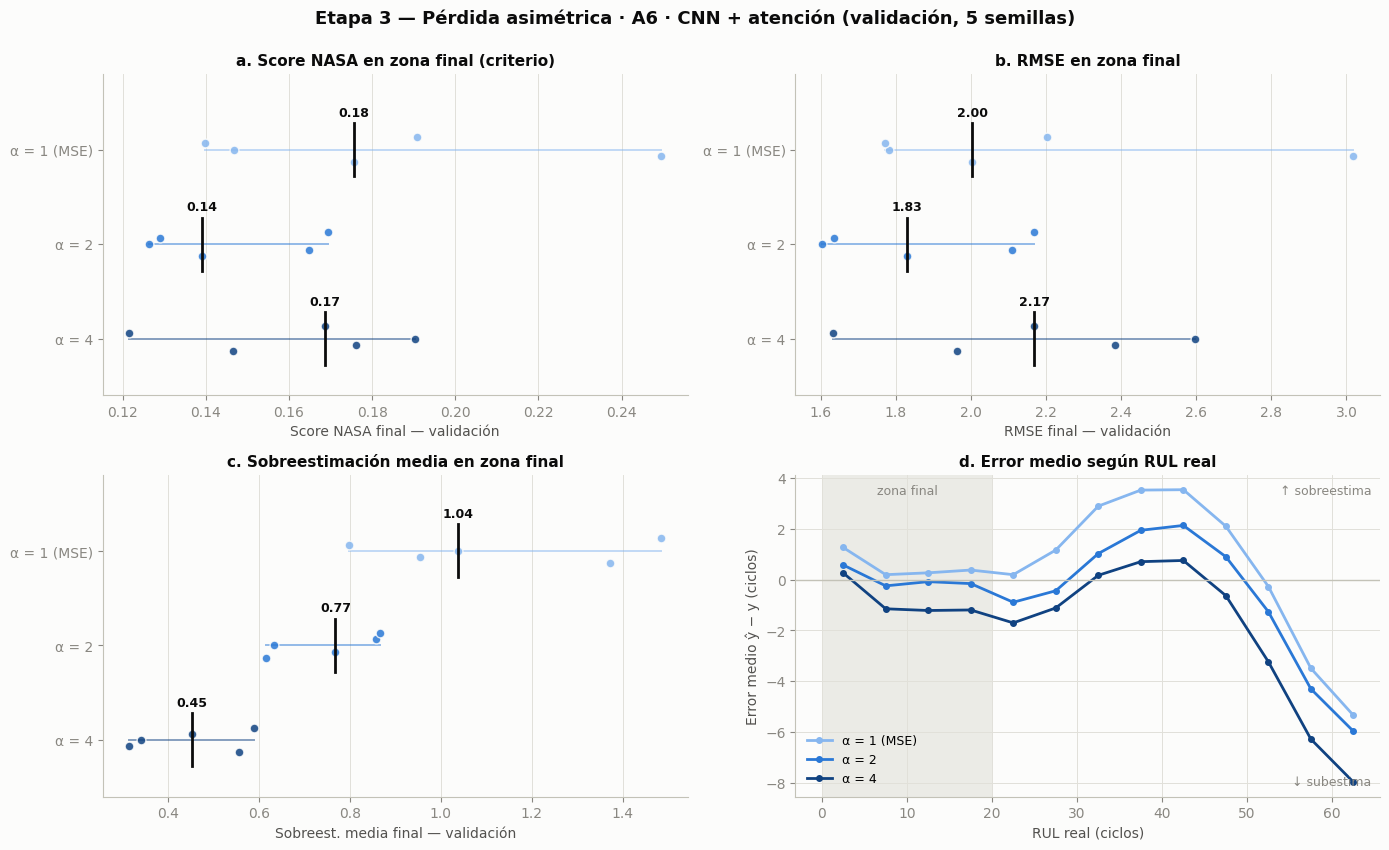

In [30]:
_alpha_cfgs = [ALPHA_LABELS[a] for a in STAGE3_ALPHAS]
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for ax, metric, title in ((axes[0, 0], "Score NASA final", "a. Score NASA en zona final (criterio)"),
                          (axes[0, 1], "RMSE final", "b. RMSE en zona final"),
                          (axes[1, 0], "Sobreest. media final", "c. Sobreestimación media en zona final")):
    seed_dotplot(ax, s3_val, metric, _alpha_cfgs, group_col="cfg", colors=ALPHA_COLORS)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} — validación")

ax = axes[1, 1]
_, _y3, _ = build_tensors(STAGE2_CHOICE, "oficial")["val"]
edges = np.arange(0, RUL_MAX + 5, 5)
centers = (edges[:-1] + edges[1:]) / 2
ax.axvspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
for a in STAGE3_ALPHAS:
    d = np.concatenate([r["val_pred"] - _y3 for r in stage3 if r["alpha"] == a])
    yt = np.tile(_y3, len(SEEDS))
    idx = np.clip(np.digitize(yt, edges) - 1, 0, len(centers) - 1)
    ax.plot(centers, [d[idx == k].mean() if np.any(idx == k) else np.nan for k in range(len(centers))],
            color=ALPHA_COLORS[ALPHA_LABELS[a]], lw=2, marker="o", ms=4, label=ALPHA_LABELS[a])
ax.axhline(0, color=AXIS, lw=1)
ax.annotate("zona final", (FINAL_ZONE / 2, 1), xycoords=("data", "axes fraction"), xytext=(0, -14),
            textcoords="offset points", ha="center", color=MUTED, fontsize=9)
ax.annotate("↑ sobreestima", (1, 1), xycoords="axes fraction", xytext=(-6, -14),
            textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax.annotate("↓ subestima", (1, 0), xycoords="axes fraction", xytext=(-6, 8),
            textcoords="offset points", ha="right", color=MUTED, fontsize=9)
ax.set_title("d. Error medio según RUL real")
ax.set_xlabel("RUL real (ciclos)")
ax.set_ylabel("Error medio ŷ − y (ciclos)")
ax.legend(loc="lower left", fontsize=9)

fig.suptitle(f"Etapa 3 — Pérdida asimétrica · {ARCH_LABELS[STAGE1_CHOICE]} (validación, 5 semillas)",
             fontsize=13, fontweight="bold", color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_perdida_asimetrica.png"), dpi=160, bbox_inches="tight")
plt.show()

### Trayectorias en la zona final

Últimos 30 ciclos de cada unidad de validación. Para cada ciclo se promedian sus
ventanas y luego se toma la mediana entre semillas.

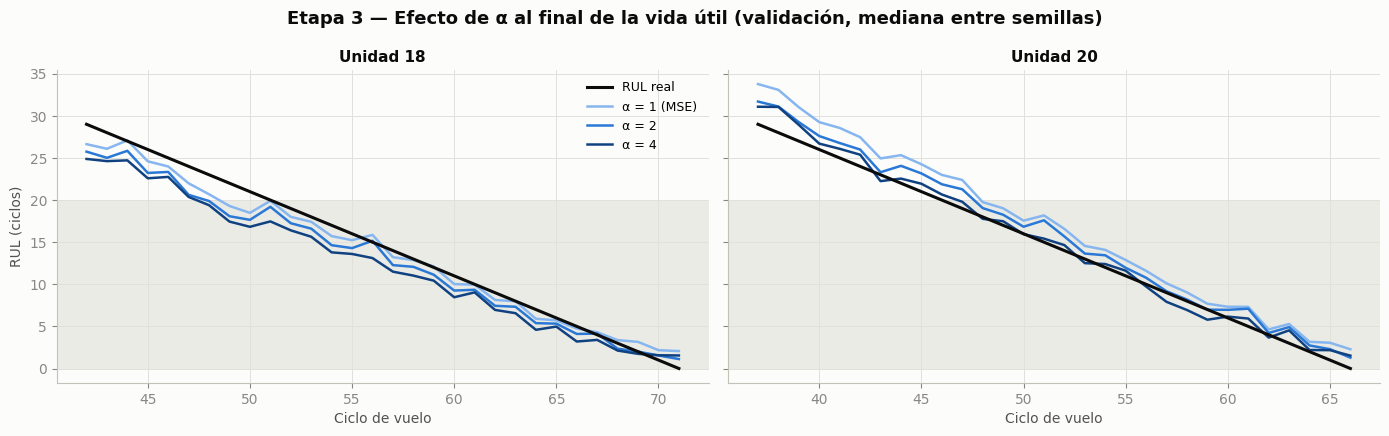

In [31]:
_, _y3, _m3v = build_tensors(STAGE2_CHOICE, "oficial")["val"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, u in zip(axes, VAL_UNITS):
    m = _m3v[:, 0] == u
    cyc = np.unique(_m3v[m, 1])
    cyc = cyc[cyc > cyc.max() - 30]
    ax.axhspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.plot(cyc, [_y3[m][_m3v[m, 1] == c].mean() for c in cyc], color=INK, lw=2.2,
            label="RUL real", zorder=4)
    for a in STAGE3_ALPHAS:
        per_seed = [[r["val_pred"][m][_m3v[m, 1] == c].mean() for c in cyc]
                    for r in stage3 if r["alpha"] == a]
        ax.plot(cyc, np.median(per_seed, axis=0), color=ALPHA_COLORS[ALPHA_LABELS[a]], lw=1.8,
                label=ALPHA_LABELS[a], zorder=3)
    ax.set_title(f"Unidad {int(u)}")
    ax.set_xlabel("Ciclo de vuelo")
axes[0].set_ylabel("RUL (ciclos)")
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 3 — Efecto de α al final de la vida útil (validación, mediana entre semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa3_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

## 3.4 Discusión

### Resultados en validación (A6 · CNN + atención, normalización global)

| Métrica | α = 1 (MSE) | **α = 2** | α = 4 |
|---|---|---|---|
| Score NASA final (criterio) | 0,18 [0,14 – 0,25] | **0,14** [0,13 – 0,17] | 0,17 [0,12 – 0,19] |
| RMSE final | 2,00 [1,77 – 3,02] | **1,83** [1,60 – 2,17] | 2,17 [1,63 – 2,60] |
| Sobreestimación media final | 1,04 [0,80 – 1,48] | 0,77 [0,62 – 0,87] | **0,45** [0,32 – 0,59] |
| % sobreestimación final | 60,9 % | 48,1 % | **36,6 %** |
| RMSE global | **4,38** [4,35 – 4,91] | 4,53 [4,43 – 4,77] | 5,30 [4,76 – 5,35] |
| RMSE zona temprana (> 40) | **5,75** | 5,97 | 7,34 |

### α = 2 mejora la zona final sin excepciones entre semillas

Aplicando el criterio pre-registrado se elige **α = 2**. Es el primer resultado del
trabajo que **no depende de la semilla**: frente a la MSE, α = 2 reduce el score NASA
final en las **5 de 5** semillas (−21 % en la mediana) y también el RMSE final en las
**5 de 5** (2,00 → 1,83). La sobreestimación media en la zona final baja un 26 %. Además,
el resultado es más estable: la peor semilla pasa de 3,02 a 2,17 ciclos de RMSE final.

### El costo está donde el profesor dijo que no importa

El RMSE global sube levemente (4,38 → 4,53) y el error en la zona temprana también
(5,75 → 5,97). El panel d muestra por qué: la pérdida desplaza toda la curva de error
hacia abajo. Con MSE, el modelo sobreestima sobre todo en la zona intermedia (hasta
+3,5 ciclos con RUL de 35–45) y algo en la zona final; con α = 2 la zona final queda
prácticamente sin sesgo, a cambio de subestimar más cuando el motor todavía está sano.
Subestimar al inicio significa anticipar una inspección, no una falla en vuelo. Es
exactamente el compromiso que el profesor consideró aceptable en la Reunión 03.

### α = 4 es demasiado conservador

α = 4 reduce más la sobreestimación (36,6 % de predicciones sobreestimadas en la zona
final, frente a 60,9 % con MSE), pero a costa de precisión: su RMSE final (2,17) es
peor que el de la MSE en la mediana, el sesgo final se vuelve negativo (subestima en
torno a 1 ciclo) y el RMSE en la zona temprana sube a 7,34. El score NASA, que pondera
ambas cosas, lo deja detrás de α = 2.

### Configuración final

**A6 (CNN + atención), normalización global, pérdida asimétrica con α = 2.** La etapa 4
la evalúa con validación cruzada contra A3 (CNN + LSTM, global, MSE) y, al cierre, una
única vez sobre el conjunto de prueba oficial.

# Etapa 4 — Validación cruzada dejando una unidad fuera

**Pregunta:** ¿la ventaja de la configuración final se mantiene en motores distintos de
los dos de validación, o depende de la partición elegida?

Se comparan dos configuraciones:

| | Arquitectura | Normalización | Pérdida | Origen |
|---|---|---|---|---|
| **Final** | elegida en la etapa 1 | elegida en la etapa 2 | α elegido en la etapa 3 | este trabajo |
| **Base** | A3 · CNN + LSTM | global | MSE (α = 1) | v01 |

**Diseño de los folds:** cada una de las 6 unidades de `dev` se evalúa una vez. En
cada fold, la unidad siguiente de la lista se usa como validación para el early
stopping, y las 4 restantes para entrenar. La normalización se reajusta en cada fold
con solo sus unidades de entrenamiento. Se usan 3 semillas por fold: 6 folds × 2
configuraciones × 3 semillas = 36 corridas.

**Limitaciones declaradas:**

- El umbral PwL (62 ciclos) se mantiene fijo en todos los folds para que las etiquetas
  sean comparables. Se calculó con las unidades 2, 5, 10 y 16, así que en los folds que
  evalúan una de ellas el umbral contiene una pequeña dependencia de esa misma unidad.
- Las 6 unidades de `dev` vuelan la misma clase (`Fc = 3`): la validación cruzada mide
  la variabilidad entre motores, no el cambio de dominio hacia otras clases de vuelo.

No hay selección en esta etapa: los resultados se reportan **por unidad**, sin
promediar entre unidades.

## 4.1 Folds y entrenamiento

In [32]:
CV_UNITS = [2.0, 5.0, 10.0, 16.0, 18.0, 20.0]
CV_SEEDS = SEEDS[:3]
FINAL_CFG = dict(arch=STAGE1_CHOICE, norm=STAGE2_CHOICE, alpha=STAGE3_CHOICE)
BASE_CFG = dict(arch="A3", norm="global", alpha=1.0)
assert FINAL_CFG != BASE_CFG
CFG_LABELS = {"final": f"Final · {STAGE1_CHOICE} + {NORM_LABELS[STAGE2_CHOICE]} + α = {STAGE3_CHOICE:g}",
              "base": "Base · A3 + global + MSE"}
CFG_COLORS = {"final": "#2a78d6", "base": ARCH_COLORS["A3"]}

rows = []
for k, u in enumerate(CV_UNITS):
    v = CV_UNITS[(k + 1) % len(CV_UNITS)]
    tr = [x for x in CV_UNITS if x not in (u, v)]
    SPLITS[f"cv_u{int(u)}"] = {"name": f"cv_u{int(u)}", "train": tr, "val": [v], "eval": [u]}
    rows.append({"Fold": k + 1, "Evaluación": int(u), "Validación": int(v),
                 "Entrenamiento": ", ".join(str(int(x)) for x in tr)})
print(pd.DataFrame(rows).to_string(index=False))


def _cfg_name(r):
    keys = ("arch", "norm", "alpha")
    return "final" if all(r[k] == FINAL_CFG[k] for k in keys) else "base"


stage4 = run_many([dict(**cfg, seed=s, split=f"cv_u{int(u)}")
                   for u in CV_UNITS for cfg in (FINAL_CFG, BASE_CFG) for s in CV_SEEDS], label="  ")
cv_df = records_to_df(stage4, "eval")
cv_df["unidad"] = cv_df["split"].str.replace("cv_u", "").astype(int)
cv_df["config"] = cv_df.apply(_cfg_name, axis=1)
cv_df.to_csv(os.path.join(OUT_DIR, "etapa4_validacion_cruzada.csv"), index=False, encoding="utf-8-sig")

 Fold  Evaluación  Validación  Entrenamiento
    1           2           5 10, 16, 18, 20
    2           5          10  2, 16, 18, 20
    3          10          16   2, 5, 18, 20
    4          16          18   2, 5, 10, 20
    5          18          20   2, 5, 10, 16
    6          20           2  5, 10, 16, 18


  A6 · global · α=2 · semilla 0 | mejor época 13/18 | caché
  A6 · global · α=2 · semilla 1 | mejor época 18/23 | caché
  A6 · global · α=2 · semilla 2 | mejor época  1/ 6 | caché
  A3 · global · α=1 · semilla 0 | mejor época 13/18 | caché
  A3 · global · α=1 · semilla 1 | mejor época  9/14 | caché
  A3 · global · α=1 · semilla 2 | mejor época  6/11 | caché


  A6 · global · α=2 · semilla 0 | mejor época  9/14 | caché
  A6 · global · α=2 · semilla 1 | mejor época  6/11 | caché
  A6 · global · α=2 · semilla 2 | mejor época 16/21 | caché
  A3 · global · α=1 · semilla 0 | mejor época 11/16 | caché
  A3 · global · α=1 · semilla 1 | mejor época  7/12 | caché
  A3 · global · α=1 · semilla 2 | mejor época  4/ 9 | caché


  A6 · global · α=2 · semilla 0 | mejor época 10/15 | caché
  A6 · global · α=2 · semilla 1 | mejor época 10/15 | caché
  A6 · global · α=2 · semilla 2 | mejor época 14/19 | caché
  A3 · global · α=1 · semilla 0 | mejor época  8/13 | caché
  A3 · global · α=1 · semilla 1 | mejor época  9/14 | caché
  A3 · global · α=1 · semilla 2 | mejor época  5/10 | caché


  A6 · global · α=2 · semilla 0 | mejor época  9/14 | caché
  A6 · global · α=2 · semilla 1 | mejor época 10/15 | caché
  A6 · global · α=2 · semilla 2 | mejor época  7/12 | caché
  A3 · global · α=1 · semilla 0 | mejor época 14/19 | caché
  A3 · global · α=1 · semilla 1 | mejor época 11/16 | caché
  A3 · global · α=1 · semilla 2 | mejor época 11/16 | caché


  A6 · global · α=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · α=2 · semilla 1 | mejor época 14/19 | caché
  A6 · global · α=2 · semilla 2 | mejor época  7/12 | caché
  A3 · global · α=1 · semilla 0 | mejor época  9/14 | caché
  A3 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · α=1 · semilla 2 | mejor época  9/14 | caché


  A6 · global · α=2 · semilla 0 | mejor época 22/27 | caché
  A6 · global · α=2 · semilla 1 | mejor época  6/11 | caché
  A6 · global · α=2 · semilla 2 | mejor época 14/19 | caché
  A3 · global · α=1 · semilla 0 | mejor época  7/12 | caché
  A3 · global · α=1 · semilla 1 | mejor época 11/16 | caché
  A3 · global · α=1 · semilla 2 | mejor época  6/11 | caché
→ 36 corridas en 0.0 min (36 desde caché)


## 4.2 Resultados por unidad

Cada celda es la mediana [mín. – máx.] sobre las 3 semillas del fold en que esa unidad
fue evaluada.

In [33]:
CV_METRICS = ["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE", "Sesgo"]
for metric in CV_METRICS:
    tab = (cv_df.groupby(["unidad", "config"])[metric].apply(med_range).unstack("config")
           [["final", "base"]].rename(columns=CFG_LABELS))
    print(f"\n{metric}")
    print(tab.to_string())

_med_u = cv_df.groupby(["unidad", "config"])[CV_METRICS].median().unstack("config")
_paired = cv_df.pivot_table(index=["unidad", "seed"], columns="config", values=CV_METRICS)
print("\nCuántas veces la configuración final es mejor que la base:")
for metric in ["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE"]:
    by_unit = int((_med_u[(metric, "final")] < _med_u[(metric, "base")]).sum())
    by_pair = int((_paired[(metric, "final")] < _paired[(metric, "base")]).sum())
    print(f"   {metric:<22} unidades (mediana): {by_unit} de {len(CV_UNITS)} | "
          f"pares unidad-semilla: {by_pair} de {len(_paired)}")


RMSE final
config Final · A6 + global + α = 2 Base · A3 + global + MSE
unidad                                                     
2               2.02 [1.80 – 4.25]       1.55 [1.55 – 1.81]
5               5.60 [4.05 – 8.01]       2.99 [2.66 – 3.48]
10              2.78 [2.57 – 3.03]       2.29 [1.70 – 2.56]
16              1.87 [1.75 – 3.74]       3.31 [2.81 – 3.53]
18              2.01 [1.68 – 2.57]       1.85 [1.60 – 1.93]
20              1.89 [1.63 – 2.32]       3.30 [2.73 – 4.00]

Score NASA final
config Final · A6 + global + α = 2 Base · A3 + global + MSE
unidad                                                     
2               0.13 [0.13 – 0.40]       0.13 [0.13 – 0.16]
5          22.58 [0.44 – 56340.05]       0.24 [0.22 – 0.29]
10              0.21 [0.18 – 0.22]       0.16 [0.13 – 0.19]
16             0.15 [0.13 – 12.21]       0.36 [0.29 – 0.40]
18              0.14 [0.12 – 0.19]       0.15 [0.13 – 0.17]
20              0.15 [0.14 – 0.19]       0.34 [0.27 – 0.46]

Sobreest.

## 4.3 Figura: validación cruzada

Una fila por unidad evaluada. Cada punto es una semilla, el trazo negro marca la
mediana; arriba la configuración final y abajo la base.

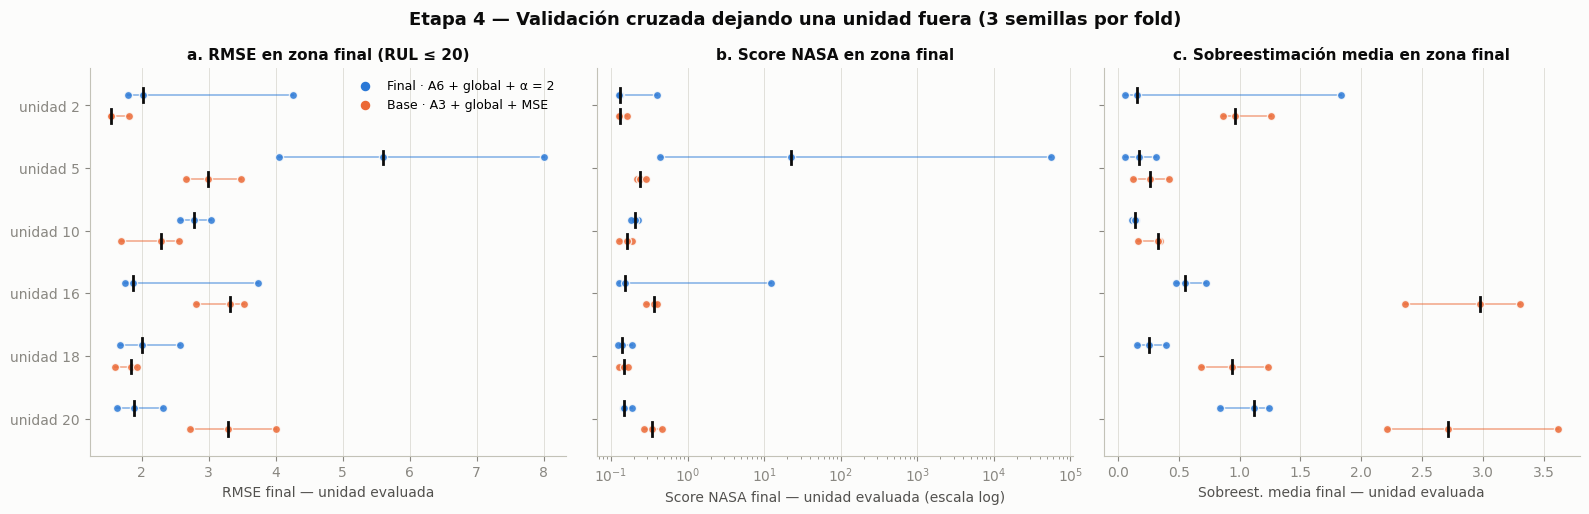

In [34]:
def paired_dotplot(ax, df, metric, rows, groups, colors):
    offs = np.linspace(0.17, -0.17, len(groups))
    for i, r in enumerate(rows):
        y0 = len(rows) - 1 - i
        for off, g in zip(offs, groups):
            v = df[(df["unidad"] == r) & (df["config"] == g)][metric].values
            if not len(v):
                continue
            ax.plot([v.min(), v.max()], [y0 + off] * 2, color=colors[g], lw=1.3, alpha=0.5, zorder=2)
            ax.scatter(v, [y0 + off] * len(v), s=34, color=colors[g], alpha=0.85,
                       edgecolor=SURFACE, linewidth=1, zorder=3)
            ax.plot([np.median(v)] * 2, [y0 + off - 0.11, y0 + off + 0.11], color=INK, lw=2, zorder=4)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([f"unidad {r}" for r in rows[::-1]])
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.grid(axis="y", visible=False)


_units = [int(u) for u in CV_UNITS]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
for ax, metric, title in ((axes[0], "RMSE final", "a. RMSE en zona final (RUL ≤ 20)"),
                          (axes[1], "Score NASA final", "b. Score NASA en zona final"),
                          (axes[2], "Sobreest. media final", "c. Sobreestimación media en zona final")):
    paired_dotplot(ax, cv_df, metric, _units, ["final", "base"], CFG_COLORS)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} — unidad evaluada")
# El score NASA es exponencial: unas pocas predicciones extremas lo llevan a valores de
# miles, así que este panel usa escala logarítmica para no aplastar el resto.
axes[1].set_xscale("log")
axes[1].set_xlabel("Score NASA final — unidad evaluada (escala log)")
for g in ("final", "base"):
    axes[0].scatter([], [], s=34, color=CFG_COLORS[g], label=CFG_LABELS[g])
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Etapa 4 — Validación cruzada dejando una unidad fuera (3 semillas por fold)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa4_validacion_cruzada.png"), dpi=160, bbox_inches="tight")
plt.show()

## 4.4 Evaluación final sobre el conjunto de prueba oficial

Unidades 11, 14 y 15, **evaluadas una sola vez**. Se reportan tres configuraciones de
la partición oficial con 5 semillas, para separar el efecto de cada cambio:

| Configuración | Qué aísla |
|---|---|
| Base · A3 + global + MSE | Punto de partida (v01) |
| A6 + global + MSE | Efecto de la arquitectura |
| Final · A6 + global + α elegido | Efecto adicional de la pérdida asimétrica |

Todas estas corridas se entrenaron en etapas anteriores, y sus predicciones sobre el
conjunto de prueba se guardaron sin consultarse. El notebook verifica que ninguna se
entrene aquí.

In [35]:
TEST_CFGS = {"base": BASE_CFG,
             "final_mse": dict(arch=STAGE1_CHOICE, norm=STAGE2_CHOICE, alpha=1.0),
             "final": FINAL_CFG}
if TEST_CFGS["final_mse"] == FINAL_CFG:          # si el α elegido fuera 1, no hay nada que aislar
    del TEST_CFGS["final_mse"]
TEST_LABELS = {"base": CFG_LABELS["base"],
               "final_mse": f"{STAGE1_CHOICE} + {NORM_LABELS[STAGE2_CHOICE]} + MSE",
               "final": CFG_LABELS["final"]}
TEST_COLORS = {"base": ARCH_COLORS["A3"], "final_mse": "#86b6ef", "final": "#2a78d6"}

test_records = run_many([dict(**c, seed=s) for c in TEST_CFGS.values() for s in SEEDS], label="  ")
if not SMOKE_TEST:
    assert all(r["cached"] for r in test_records), "una corrida de prueba se entrenó en esta etapa"
    print("OK: las 15 corridas ya existían: el conjunto de prueba no influyó en ninguna decisión.")

test_df = records_to_df(test_records, "eval")
_inv = {tuple(c[k] for k in ("arch", "norm", "alpha")): n for n, c in TEST_CFGS.items()}
test_df["config"] = test_df.apply(lambda r: _inv[(r["arch"], r["norm"], r["alpha"])], axis=1)
test_df["cfg"] = test_df["config"].map(TEST_LABELS)
test_df.to_csv(os.path.join(OUT_DIR, "prueba_oficial.csv"), index=False, encoding="utf-8-sig")

print("\nPrueba oficial (unidades 11, 14, 15) — mediana [mín. – máx.] sobre 5 semillas")
display(summary_table(test_df, "cfg", MAIN_METRICS + ["% sobreest. final"]))
print("\nRMSE en zona final por unidad de prueba")
display(summary_table(test_df, "cfg", ["RMSE final u11", "RMSE final u14", "RMSE final u15"]))

_mt = test_df.groupby("config")[["RMSE final", "Score NASA final", "Sobreest. media final", "RMSE"]].median()
selection["decisiones"]["etapa_4"] = {
    "validacion_cruzada_rmse_final_mediana_por_unidad": {
        str(int(u)): {c: round(float(_med_u[("RMSE final", c)].loc[int(u)]), 4) for c in ("final", "base")}
        for u in CV_UNITS},
    "prueba_oficial_mediana": {c: {m: round(float(_mt.loc[c, m]), 4) for m in _mt.columns}
                               for c in TEST_CFGS},
}
if not SMOKE_TEST:
    with open(SELECTION_FILE, "w", encoding="utf-8") as fh:
        json.dump(selection, fh, ensure_ascii=False, indent=2)

  A3 · global · α=1 · semilla 0 | mejor época 18/23 | caché
  A3 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A3 · global · α=1 · semilla 2 | mejor época  9/14 | caché
  A3 · global · α=1 · semilla 3 | mejor época  5/10 | caché
  A3 · global · α=1 · semilla 4 | mejor época 10/15 | caché
  A6 · global · α=1 · semilla 0 | mejor época 13/18 | caché
  A6 · global · α=1 · semilla 1 | mejor época  6/11 | caché
  A6 · global · α=1 · semilla 2 | mejor época 25/30 | caché
  A6 · global · α=1 · semilla 3 | mejor época 16/21 | caché
  A6 · global · α=1 · semilla 4 | mejor época 30/30 | caché
  A6 · global · α=2 · semilla 0 | mejor época  8/13 | caché
  A6 · global · α=2 · semilla 1 | mejor época 13/18 | caché
  A6 · global · α=2 · semilla 2 | mejor época 12/17 | caché
  A6 · global · α=2 · semilla 3 | mejor época 18/23 | caché
  A6 · global · α=2 · semilla 4 | mejor época 15/20 | caché
→ 15 corridas en 0.0 min (15 desde caché)
OK: las 15 corridas ya existían: el conjunto de prueba no 

,cfg,n,RMSE final,Sobreest. media final,Score NASA final,RMSE,Sesgo,% sobreest. final
0,Base · A3 + global + MSE,5,2.97 [2.47 – 3.30],2.35 [1.47 – 2.71],0.29 [0.21 – 0.34],6.01 [5.54 – 6.61],3.00 [1.40 – 3.67],86.03 [64.03 – 91.94]
1,A6 + global + MSE,5,2.16 [1.92 – 2.45],1.60 [1.05 – 2.10],0.19 [0.17 – 0.24],5.28 [4.99 – 5.60],1.24 [1.11 – 1.77],82.47 [58.10 – 97.02]
2,Final · A6 + global + α = 2,5,1.78 [1.50 – 1.97],1.00 [0.71 – 1.47],0.14 [0.12 – 0.18],5.34 [4.95 – 5.56],0.19 [-0.65 – 0.46],67.40 [58.85 – 85.66]



RMSE en zona final por unidad de prueba


,cfg,n,RMSE final u11,RMSE final u14,RMSE final u15
0,Base · A3 + global + MSE,5,3.45 [2.76 – 3.54],2.23 [1.72 – 3.79],2.13 [2.07 – 2.62]
1,A6 + global + MSE,5,2.33 [2.03 – 2.71],2.25 [1.64 – 2.40],1.71 [1.57 – 1.99]
2,Final · A6 + global + α = 2,5,1.86 [1.39 – 2.20],1.32 [0.84 – 2.43],1.49 [1.35 – 1.73]


## 4.5 Figuras: prueba oficial

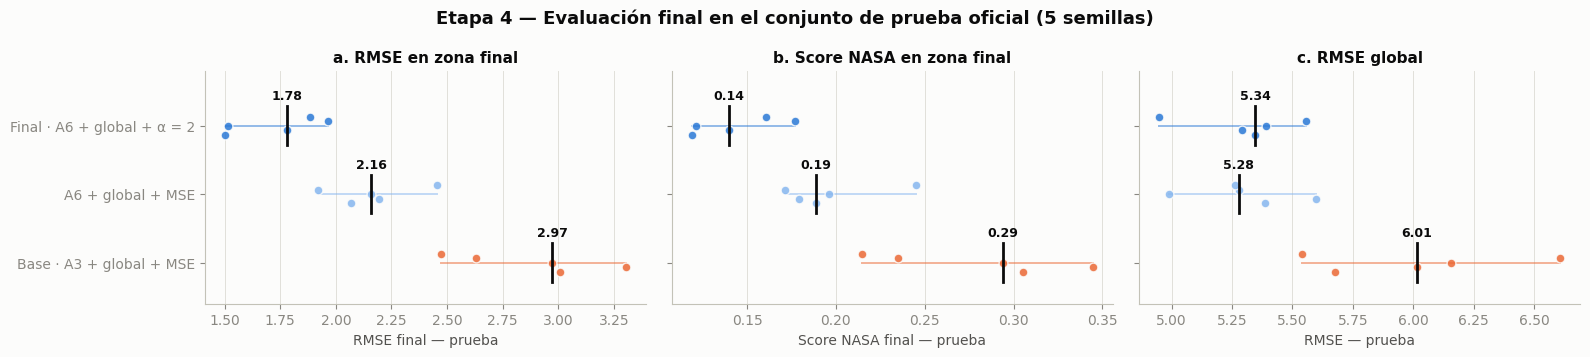

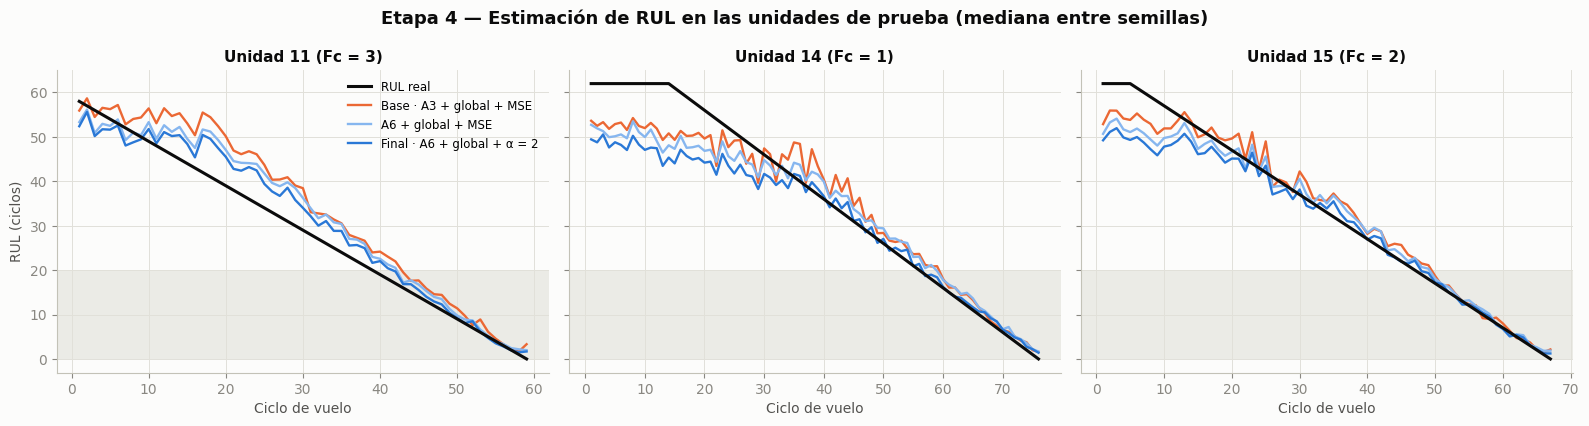

In [36]:
_tcfgs = [TEST_LABELS[c] for c in ("final", "final_mse", "base") if c in TEST_CFGS]
_tcolors = {TEST_LABELS[c]: TEST_COLORS[c] for c in TEST_CFGS}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, metric, title in ((axes[0], "RMSE final", "a. RMSE en zona final"),
                          (axes[1], "Score NASA final", "b. Score NASA en zona final"),
                          (axes[2], "RMSE", "c. RMSE global")):
    seed_dotplot(ax, test_df, metric, _tcfgs, group_col="cfg", colors=_tcolors)
    ax.set_title(title)
    ax.set_xlabel(f"{metric} — prueba")
fig.suptitle("Etapa 4 — Evaluación final en el conjunto de prueba oficial (5 semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa4_prueba_metricas.png"), dpi=160, bbox_inches="tight")
plt.show()

_, _yt, _mt_meta = build_tensors("global", "oficial")["eval"]
_test_units = sorted(np.unique(_mt_meta[:, 0]))
fig, axes = plt.subplots(1, len(_test_units), figsize=(16, 4.3), sharey=True)
for ax, u in zip(axes, _test_units):
    m = _mt_meta[:, 0] == u
    cyc = np.unique(_mt_meta[m, 1])
    ax.axhspan(0, FINAL_ZONE, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.plot(cyc, [_yt[m][_mt_meta[m, 1] == c].mean() for c in cyc], color=INK, lw=2.2,
            label="RUL real", zorder=4)
    for name in [c for c in ("base", "final_mse", "final") if c in TEST_CFGS]:
        recs = [r for r in test_records if _inv[(r["arch"], r["norm"], r["alpha"])] == name]
        per_seed = [[r["eval_pred"][m][_mt_meta[m, 1] == c].mean() for c in cyc] for r in recs]
        ax.plot(cyc, np.median(per_seed, axis=0), color=TEST_COLORS[name], lw=1.7,
                label=TEST_LABELS[name], zorder=3)
    ax.set_title(f"Unidad {int(u)} (Fc = {int(np.unique(test['fc'][test['unit'] == u])[0])})")
    ax.set_xlabel("Ciclo de vuelo")
axes[0].set_ylabel("RUL (ciclos)")
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Etapa 4 — Estimación de RUL en las unidades de prueba (mediana entre semillas)",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "etapa4_prueba_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

## 4.6 Discusión

### Prueba oficial: la configuración final gana con claridad

| Configuración | RMSE final | Score NASA final | Sesgo | RMSE global |
|---|---|---|---|---|
| Base · A3 + global + MSE | 2,97 [2,47 – 3,30] | 0,29 [0,21 – 0,34] | +3,00 | 6,01 |
| A6 + global + MSE | 2,16 [1,92 – 2,45] | 0,19 [0,17 – 0,24] | +1,24 | 5,28 |
| **Final · A6 + global + α = 2** | **1,78** [1,50 – 1,97] | **0,14** [0,12 – 0,18] | **+0,19** | 5,34 |

- **Los rangos no se solapan:** la peor semilla de la configuración final (1,97) es
  mejor que la mejor semilla de la base (2,47).
- **Mejoran las tres unidades de prueba**, incluidas la 14 y la 15, que vuelan clases
  de vuelo nunca vistas en entrenamiento. RMSE final de la base frente a la final:
  unidad 11, 3,45 → 1,86; unidad 14, 2,23 → 1,32; unidad 15, 2,13 → 1,49.
- **Cada cambio aporta.** La arquitectura reduce el RMSE final de 2,97 a 2,16, y la
  pérdida asimétrica lo reduce de 2,16 a 1,78. El sesgo en prueba pasa de +3,00
  (optimista) a prácticamente cero.
- **El costo, de nuevo, está al inicio de la vida útil:** el RMSE en la zona temprana
  sube (6,67 con A6 + MSE frente a 7,72 con la final), sin cambio relevante en el RMSE
  global.

### Validación cruzada: la ventaja depende del motor

| Unidad | RMSE final, final | RMSE final, base | Sesgo de la base | Resultado |
|---|---|---|---|---|
| 2 | 2,02 [1,80 – 4,25] | 1,55 [1,55 – 1,81] | +2,18 | peor |
| 5 | 5,60 [4,05 – 8,01] | 2,99 [2,66 – 3,48] | −3,71 | peor |
| 10 | 2,78 [2,57 – 3,03] | 2,29 [1,70 – 2,57] | −4,10 | peor |
| 16 | 1,87 [1,75 – 3,74] | 3,31 [2,82 – 3,53] | +3,60 | **mejor** |
| 18 | 2,01 [1,68 – 2,57] | 1,85 [1,60 – 1,93] | −0,30 | peor |
| 20 | 1,89 [1,63 – 2,32] | 3,30 [2,73 – 4,00] | +4,75 | **mejor** |

Comparando unidad y semilla, la configuración final tiene menor RMSE final en solo 7 de
18 casos. En cambio, **reduce la sobreestimación en la zona final en 16 de 18**, que es
el objetivo declarado de la pérdida asimétrica (criterio C4).

La columna de sesgo de la base explica el patrón. La pérdida asimétrica desplaza las
predicciones hacia abajo. Eso ayuda donde el modelo base era **optimista** (unidades 16
y 20, con sesgo de +3,6 y +4,8) y perjudica donde ya era **pesimista** (unidades 5 y 10,
con −3,7 y −4,1). El conjunto de prueba oficial cae del lado favorable: ahí la base
sobreestima (+3,00), y por eso la ganancia es tan clara. La única excepción al patrón
es la unidad 2, con sesgo base positivo pero resultado peor, donde la configuración
final tiene una semilla atípica (4,25).

### Robustez: A6 puede producir predicciones absurdas

En los folds de las unidades 5, 16 y 2, algunas semillas de A6 producen unas pocas
predicciones de hasta 189 ciclos, cuando el RUL máximo posible es 62. A3 nunca supera
los 60. Son pocas ventanas, pero el score NASA, exponencial, llega a 56 340 en el fold
de la unidad 5. La causa probable es estructural: A6 no tiene ninguna capa que sature
su salida, mientras que el LSTM de A3 acota sus estados internos con `tanh`. Ante
ventanas fuera de la distribución de entrenamiento, A6 puede extrapolar sin límite.

Un diagnóstico, que no modifica ningún resultado reportado, muestra que recortar las
predicciones al rango válido [0, 62] solo cambia la unidad 5 (RMSE final 5,60 → 4,94).
Los valores extremos explican la explosión del score NASA, pero no el patrón general,
que se debe al sesgo. Acotar la salida del modelo es una mejora natural, pero
aplicarla ahora, después de ver la prueba, sería una decisión posterior a los
resultados: queda como trabajo futuro.

### Conclusión de la etapa

La configuración final (A6 + global + α = 2) es la mejor en validación y en la prueba
oficial, con un margen que ninguna semilla contradice. La validación cruzada matiza
ese resultado: **la pérdida asimétrica cumple siempre su objetivo** de reducir la
sobreestimación, pero su efecto sobre la precisión depende de si el modelo tiende a
ser optimista o pesimista con cada motor. Con solo 6 motores en `dev`, todos de la misma
clase de vuelo, esa dependencia es la principal incertidumbre que hay que declarar al
presentar el resultado.

# Etapa 5 — Diagramas didácticos

Los diagramas están en `Diagramas.md` (Mermaid), en la misma carpeta que este
notebook. Usan un color fijo por tipo de bloque (datos, preprocesamiento, convolución,
LSTM, atención, agregación, cabezal y evaluación), y los porcentajes de la
partición, de modo que se puedan reutilizar en la memoria y en la presentación.

| # | Diagrama | Contenido |
|---|---|---|
| 1 | Visión general | Las etapas 0–4, la decisión de cada una y el resultado final |
| 2 | Pipeline de datos | Carga, partición por motor (55,3 / 25,5 / 19,2 %), preprocesamiento, tensores y zonas de evaluación |
| 3 | Catálogo de arquitecturas | A1–A6 en filas paralelas, con parámetros y referencias, y la tabla de pares de la ablación |
| 4 | Módulo de atención | Cálculo de los pesos αₜ y del vector de contexto |
| 5 | Normalizaciones | Global, N1a y N1b: qué aprende cada una y su resultado |
| 6 | Pérdida asimétrica | Ponderación del error según su signo y tabla de α |
| 7 | Validación cruzada | Estructura de un fold y tabla de los 6 folds |
| 8 | Resultado en prueba | Aporte de la arquitectura y de la pérdida sobre la base de v01 |

Para verlos en VS Code se necesita una extensión que renderice Mermaid en la vista
previa de Markdown (por ejemplo, *Markdown Preview Mermaid Support*). Para exportarlos
como imagen para la memoria se puede usar [mermaid.live](https://mermaid.live).

# Etapa 6 — Consolidación y defensa

Esta etapa no entrena nada: reúne las decisiones y los resultados de las etapas 1 a 4,
y declara las conclusiones, las limitaciones y el trabajo futuro. Las preguntas
probables de la defensa, con sus respuestas, están en `Preparacion_Defensa.md`.

## 6.1 Tabla de decisiones

Cada decisión se tomó con un criterio fijado antes de ver los resultados
(`results/seleccion.json`) y usando solo el conjunto de validación.

In [37]:
_d = selection["decisiones"]
decisions = pd.DataFrame([
    {"Etapa": 1, "Factor": "Arquitectura",
     "Opciones": "A4, A5, A6 (con atención); A3 como referencia",
     "Elección": f"{_d['etapa_1']['arquitectura_elegida']} · {_d['etapa_1']['nombre']}",
     "Evidencia (validación)": f"RMSE final {_d['etapa_1']['mediana_rmse_final_val']:.2f} frente a "
                               f"{_d['etapa_1']['mediana_rmse_final_val_A3']:.2f} de A3; mejor que A3 en "
                               f"{_d['etapa_1']['semillas_mejor_que_A3']} de {len(SEEDS)} semillas"},
    {"Etapa": 2, "Factor": "Normalización",
     "Opciones": "global, N1a (régimen), N1b (motor)",
     "Elección": _d["etapa_2"]["normalizacion_elegida"],
     "Evidencia (validación)": "RMSE final: " + ", ".join(
         f"{NORM_LABELS[k]} {v:.2f}" for k, v in _d["etapa_2"]["mediana_rmse_final_val"].items())},
    {"Etapa": 3, "Factor": "Pérdida",
     "Opciones": "α = 1 (MSE), 2, 4",
     "Elección": f"α = {_d['etapa_3']['alpha_elegido']:g}",
     "Evidencia (validación)": "Score NASA final: " + ", ".join(
         f"α={k} {v:.3f}" for k, v in _d["etapa_3"]["mediana_score_nasa_final_val"].items())},
])
pd.set_option("display.max_colwidth", None)
display(decisions)

_all_ids = {r["id"] for recs in (stage1, stage2, stage3, stage4, test_records) for r in recs}
print(f"Entrenamientos distintos en todo el estudio: {len(_all_ids)}")
print(f"Configuración final: {CFG_LABELS['final']}")

,Etapa,Factor,Opciones,Elección,Evidencia (validación)
0,1,Arquitectura,"A4, A5, A6 (con atención); A3 como referencia",A6 · CNN + atención,RMSE final 2.00 frente a 2.60 de A3; mejor que A3 en 4 de 5 semillas
1,2,Normalización,"global, N1a (régimen), N1b (motor)",global,"RMSE final: global 2.00, N1a régimen 2.02, N1b motor 3.29"
2,3,Pérdida,"α = 1 (MSE), 2, 4",α = 2,"Score NASA final: α=1 0.176, α=2 0.139, α=4 0.169"


Entrenamientos distintos en todo el estudio: 96
Configuración final: Final · A6 + global + α = 2


## 6.2 Resumen de resultados

Mediana [mín. – máx.] sobre 5 semillas. La validación se usó para decidir; la prueba
oficial se evaluó una sola vez, al cierre de la etapa 4.

In [38]:
def _val_values(cfg, metric):
    src = s3_val if cfg["alpha"] != 1.0 else s1_val
    sub = src[(src["arch"] == cfg["arch"]) & (src["alpha"] == cfg["alpha"]) & (src["norm"] == cfg["norm"])]
    return sub[metric].values


rows = []
for name, cfg in TEST_CFGS.items():
    t = test_df[test_df["config"] == name]
    rows.append({
        "Configuración": TEST_LABELS[name],
        "Validación · RMSE final": med_range(_val_values(cfg, "RMSE final")),
        "Prueba · RMSE final": med_range(t["RMSE final"]),
        "Prueba · Score NASA final": med_range(t["Score NASA final"]),
        "Prueba · Sobreest. media final": med_range(t["Sobreest. media final"]),
        "Prueba · Sesgo": med_range(t["Sesgo"]),
        "Prueba · RMSE global": med_range(t["RMSE"]),
    })
display(pd.DataFrame(rows))

_f = cv_df[cv_df["config"] == "final"].groupby("unidad")["RMSE final"].median()
_b = cv_df[cv_df["config"] == "base"].groupby("unidad")["RMSE final"].median()
print("Validación cruzada (RMSE final, mediana por unidad): la configuración final es mejor en "
      f"{int((_f < _b).sum())} de {len(_f)} unidades "
      f"({', '.join(str(u) for u in _f.index[_f < _b])}).")

,Configuración,Validación · RMSE final,Prueba · RMSE final,Prueba · Score NASA final,Prueba · Sobreest. media final,Prueba · Sesgo,Prueba · RMSE global
0,Base · A3 + global + MSE,2.60 [2.26 – 2.74],2.97 [2.47 – 3.30],0.29 [0.21 – 0.34],2.35 [1.47 – 2.71],3.00 [1.40 – 3.67],6.01 [5.54 – 6.61]
1,A6 + global + MSE,2.00 [1.77 – 3.02],2.16 [1.92 – 2.45],0.19 [0.17 – 0.24],1.60 [1.05 – 2.10],1.24 [1.11 – 1.77],5.28 [4.99 – 5.60]
2,Final · A6 + global + α = 2,1.83 [1.60 – 2.17],1.78 [1.50 – 1.97],0.14 [0.12 – 0.18],1.00 [0.71 – 1.47],0.19 [-0.65 – 0.46],5.34 [4.95 – 5.56]


Validación cruzada (RMSE final, mediana por unidad): la configuración final es mejor en 2 de 6 unidades (16, 20).


## 6.3 Conclusiones

1. **El protocolo importa más que la arquitectura.** La mejora del 26 % reportada en la
   primera versión del pipeline era un artefacto de fuga de datos entre unidades y de
   no seleccionar la mejor época. Con partición por motor, normalización sin fuga,
   early stopping y varias semillas, las diferencias entre arquitecturas son pequeñas.
2. **En la zona final, cinco de las seis arquitecturas son indistinguibles.** Una CNN
   simple de 10 mil parámetros rinde como la arquitectura híbrida con atención de 33
   mil. La única que se separa es la CNN + LSTM sin atención, y hacia peor.
3. **La atención no aporta un beneficio uniforme.** Mejora a la CNN + LSTM, no cambia la
   zona final de la CNN y empeora levemente a la LSTM. En la arquitectura elegida, sus
   pesos son casi uniformes, de modo que se comporta como un promedio temporal.
4. **Normalizar por condición de operación no mejoró.** La normalización por régimen
   empata con la global; la línea base por motor empeora con claridad. No fue posible
   normalizar por clase de vuelo, porque todas las unidades de desarrollo comparten la
   misma.
5. **La pérdida asimétrica es el aporte más sólido.** Con α = 2 mejora la zona final en
   las 5 semillas en validación, y en la prueba oficial lleva el RMSE final de 2,16 a
   1,78 y el sesgo de +1,24 a +0,19. Su costo es una mayor subestimación al inicio de
   la vida útil, que es el error operacionalmente barato.
6. **La configuración final supera a la base en la prueba oficial sin excepciones entre
   semillas** (RMSE final de 1,78 frente a 2,97), incluidas las dos unidades con clases
   de vuelo nunca vistas en entrenamiento.
7. **Esa ventaja no es uniforme entre motores.** En la validación cruzada, la
   configuración final es mejor en solo 2 de 6 unidades, aunque reduce la
   sobreestimación en 16 de 18 casos. La pérdida asimétrica ayuda donde el modelo base
   es optimista y perjudica donde ya es pesimista.

## 6.4 Limitaciones

- **La ablación de arquitecturas no es estricta.** Los pares con y sin atención
  (A1–A6, A2–A4, A3–A5) sí difieren en un solo factor. Pero entre extractores cambian
  varias cosas a la vez: A1 y A6 tienen una segunda convolución que A3 y A5 no tienen,
  la agregación sin atención es el promedio en A1 y el último estado en A2 y A3, y el
  dropout cambia de posición. Las comparaciones entre extractores, y en parte la
  elección de A6, están afectadas por esto.
- **Un solo subconjunto y pocos motores.** Todo el estudio usa DS02: 6 motores de
  desarrollo, todos de la clase de vuelo 3, y 3 de prueba. Ni la validación ni la
  validación cruzada pueden medir el cambio de dominio hacia otras clases de vuelo.
- **Pocas semillas.** Cinco por configuración (tres en la validación cruzada). Por eso se
  reportan valores individuales, medianas y rangos, sin pruebas de significancia.
- **Hiperparámetros no ajustados.** Tasa de aprendizaje, tamaño de ventana, submuestreo
  y tamaños de capa se fijaron de antemano y no se optimizaron por arquitectura.
- **Límite de épocas.** A6 alcanzó las 30 épocas en una semilla sin activar el early
  stopping; su resultado en la etapa 1 podría estar subestimado.
- **Salida no acotada.** A6 produjo predicciones de hasta 189 ciclos (el máximo posible
  es 62) en algunos folds de la validación cruzada.
- **Umbral PwL fijo en la validación cruzada.** Se calculó con las unidades 2, 5, 10 y 16
  y se mantuvo en todos los folds.
- **Un factor por etapa.** No se exploraron interacciones: la mejor normalización o el
  mejor α podrían ser otros para una arquitectura distinta de la elegida.

## 6.5 Trabajo futuro

1. **Ablación estricta:** tres extractores (CNN, LSTM, CNN + LSTM) por dos agregaciones
   (promedio, atención), con bloques idénticos en todas las combinaciones.
2. **Acotar la salida del modelo** al rango válido de RUL, para eliminar las
   predicciones extremas.
3. **Más subconjuntos de N-CMAPSS** (DS01 a DS08), para entrenar con varias clases de
   vuelo y poder evaluar tanto el cambio de dominio como la normalización por `Fc`.
4. **Normalización continua por condición de operación** (por ejemplo, restar una
   regresión de cada sensor sobre W), en lugar de regímenes discretos.
5. **Asimetría dependiente del RUL:** penalizar la sobreestimación solo cerca del
   fallo, para no pagar el costo en la zona temprana.
6. **Más semillas y un límite de épocas mayor**, para resolver diferencias pequeñas.